<a href="https://colab.research.google.com/github/fahadCoder/speech-emotion-recognition/blob/main/speech_emotion_recognition.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Import libraries
import librosa
import librosa.display
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from matplotlib.pyplot import specgram
import pandas as pd
import glob
from sklearn.metrics import confusion_matrix
import IPython.display as ipd  # To play sound in the notebook
import os
import sys
import warnings
# ignore warnings
if not sys.warnoptions:
    warnings.simplefilter("ignore")
warnings.filterwarnings("ignore", category=DeprecationWarning)

In [ ]:
#for dirname, _, filenames in os.walk('/kaggle/input'):
#    for filename in filenames:
#        print(os.path.join(dirname, filename))

TESS = "../../dataset/Tess/TESS_Toronto_emotional_speech_set_data/"
RAV = "../../dataset/Ravdess/audio_speech_actors_01-24/"
SAVEE = "../../dataset/Savee/ALL/"

# Run one example
dir_list = os.listdir(SAVEE)
dir_list[0:5]

['DC_a01.wav', 'DC_a02.wav', 'DC_a03.wav', 'DC_a04.wav', 'DC_a05.wav']

In [ ]:
# Get the data location for SAVEE
dir_list = os.listdir(SAVEE)

# parse the filename to get the emotions
emotion=[]
path = []
for i in dir_list:
    if i[-8:-6]=='_a':
        emotion.append('male_angry')
    elif i[-8:-6]=='_d':
        emotion.append('male_disgust')
    elif i[-8:-6]=='_f':
        emotion.append('male_fear')
    elif i[-8:-6]=='_h':
        emotion.append('male_happy')
    elif i[-8:-6]=='_n':
        emotion.append('male_neutral')
    elif i[-8:-6]=='sa':
        emotion.append('male_sad')
    elif i[-8:-6]=='su':
        emotion.append('male_surprise')
    else:
        emotion.append('male_error')
    path.append(SAVEE + i)

# Now check out the label count distribution
SAVEE_df = pd.DataFrame(emotion, columns = ['labels'])
SAVEE_df['source'] = 'SAVEE'
SAVEE_df = pd.concat([SAVEE_df, pd.DataFrame(path, columns = ['path'])], axis = 1)
SAVEE_df.labels.value_counts()

male_neutral     120
male_angry        60
male_disgust      60
male_fear         60
male_happy        60
male_sad          60
male_surprise     60
Name: labels, dtype: int64

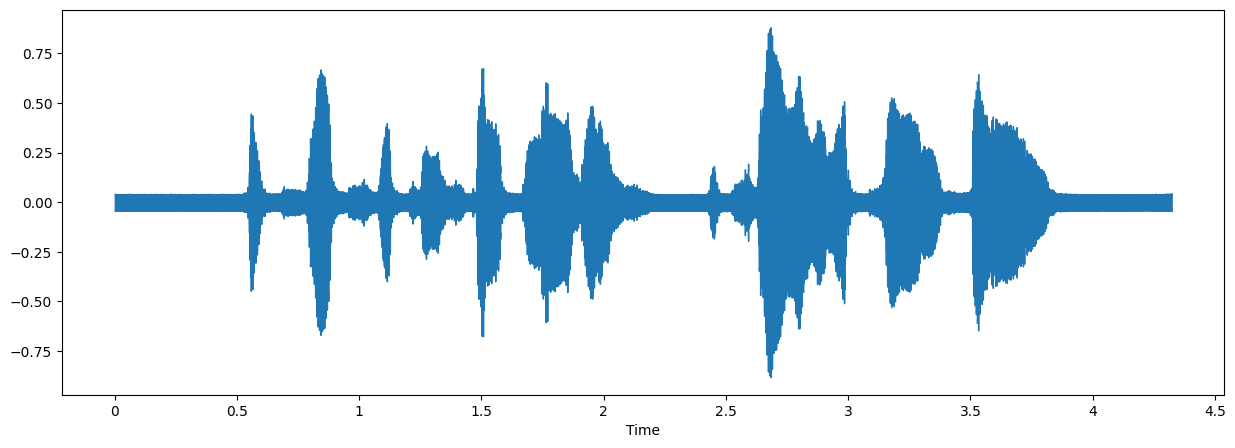

In [ ]:
import librosa
import librosa.display
import matplotlib.pyplot as plt
import IPython.display as ipd

fname = SAVEE + 'DC_f11.wav'
data, sampling_rate = librosa.load(fname)

plt.figure(figsize=(15, 5))
librosa.display.waveshow(data, sr=sampling_rate)

# Let's play the audio
ipd.Audio(fname)


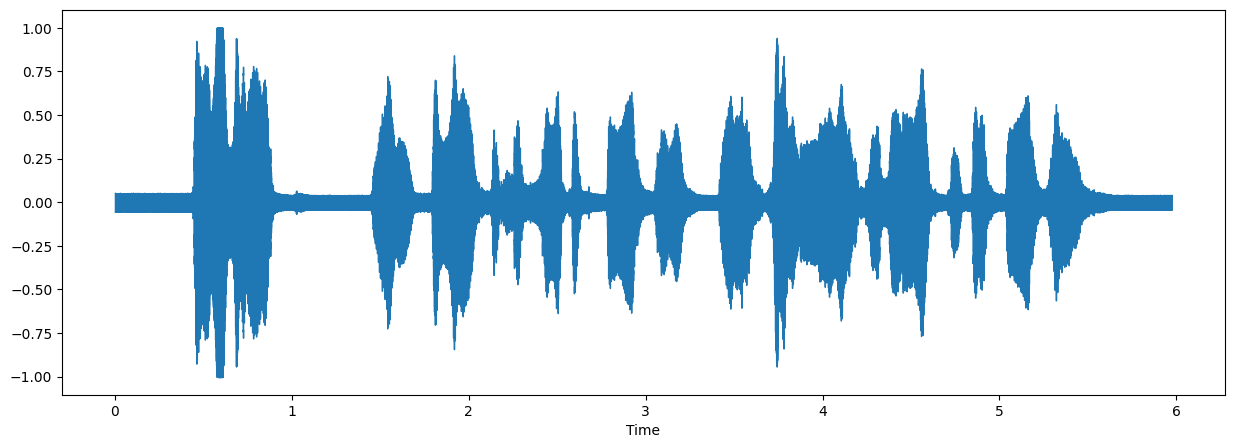

In [ ]:
# Lets play a happy track
fname = SAVEE + 'DC_h11.wav'
data, sampling_rate = librosa.load(fname)
plt.figure(figsize=(15, 5))
librosa.display.waveshow(data, sr=sampling_rate)

# Lets play the audio
ipd.Audio(fname)

In [ ]:
dir_list = os.listdir(RAV)
dir_list.sort()

emotion = []
gender = []
path = []
for i in dir_list:
    fname = os.listdir(RAV + i)
    for f in fname:
        part = f.split('.')[0].split('-')
        emotion.append(int(part[2]))
        temp = int(part[6])
        if temp%2 == 0:
            temp = "female"
        else:
            temp = "male"
        gender.append(temp)
        path.append(RAV + i + '/' + f)


RAV_df = pd.DataFrame(emotion)
RAV_df = RAV_df.replace({1:'neutral', 2:'neutral', 3:'happy', 4:'sad', 5:'angry', 6:'fear', 7:'disgust', 8:'surprise'})
RAV_df = pd.concat([pd.DataFrame(gender),RAV_df],axis=1)
RAV_df.columns = ['gender','emotion']
RAV_df['labels'] =RAV_df.gender + '_' + RAV_df.emotion
RAV_df['source'] = 'RAVDESS'
RAV_df = pd.concat([RAV_df,pd.DataFrame(path, columns = ['path'])],axis=1)
RAV_df = RAV_df.drop(['gender', 'emotion'], axis=1)
RAV_df.labels.value_counts()

male_neutral       144
female_neutral     144
male_happy          96
male_sad            96
male_angry          96
male_fear           96
male_disgust        96
male_surprise       96
female_happy        96
female_sad          96
female_angry        96
female_fear         96
female_disgust      96
female_surprise     96
Name: labels, dtype: int64

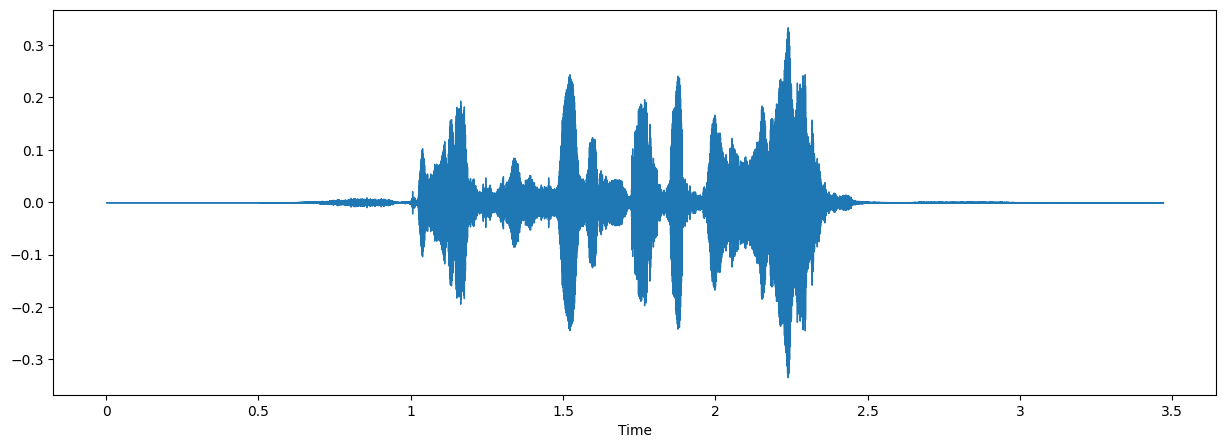

In [ ]:
# Pick a fearful track
fname = RAV + 'Actor_14/03-01-06-02-02-02-14.wav'
data, sampling_rate = librosa.load(fname)
plt.figure(figsize=(15, 5))
librosa.display.waveshow(data, sr=sampling_rate)

# Lets play the audio
ipd.Audio(fname)

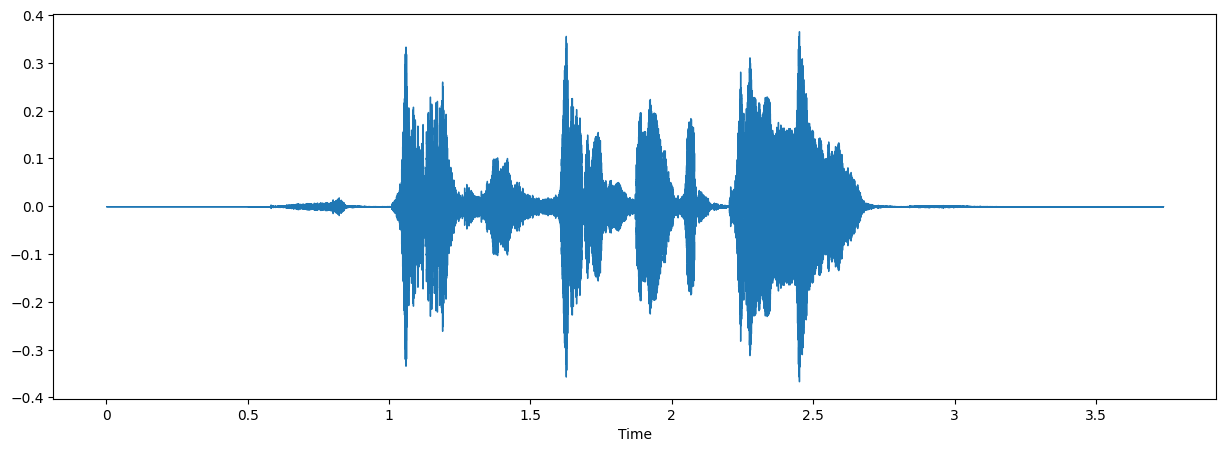

In [ ]:
# Pick a happy track
fname = RAV + 'Actor_14/03-01-03-02-02-02-14.wav'
data, sampling_rate = librosa.load(fname)
plt.figure(figsize=(15, 5))
librosa.display.waveshow(data, sr=sampling_rate)

# Lets play the audio
ipd.Audio(fname)

In [ ]:
dir_list = os.listdir(TESS)
dir_list.sort()
dir_list

['OAF_angry',
 'OAF_disgust',
 'OAF_fear',
 'OAF_happy',
 'OAF_neutral',
 'OAF_sad',
 'OAF_surprise',
 'YAF_angry',
 'YAF_disgust',
 'YAF_fear',
 'YAF_happy',
 'YAF_neutral',
 'YAF_sad',
 'YAF_surprise']

In [ ]:
path = []
emotion = []

for i in dir_list:
    fname = os.listdir(TESS + i)
    for f in fname:
        if i == 'OAF_angry' or i == 'YAF_angry':
            emotion.append('female_angry')
        elif i == 'OAF_disgust' or i == 'YAF_disgust':
            emotion.append('female_disgust')
        elif i == 'OAF_Fear' or i == 'YAF_fear':
            emotion.append('female_fear')
        elif i == 'OAF_happy' or i == 'YAF_happy':
            emotion.append('female_happy')
        elif i == 'OAF_neutral' or i == 'YAF_neutral':
            emotion.append('female_neutral')
        elif i == 'OAF_Pleasant_surprise' or i == 'YAF_pleasant_surprised':
            emotion.append('female_surprise')
        elif i == 'OAF_Sad' or i == 'YAF_sad':
            emotion.append('female_sad')
        else:
            emotion.append('Unknown')
        path.append(TESS + i + "/" + f)

TESS_df = pd.DataFrame(emotion, columns = ['labels'])
TESS_df['source'] = 'TESS'
TESS_df = pd.concat([TESS_df,pd.DataFrame(path, columns = ['path'])],axis=1)
TESS_df.labels.value_counts()

Unknown           800
female_angry      400
female_disgust    400
female_happy      400
female_neutral    400
female_fear       200
female_sad        200
Name: labels, dtype: int64

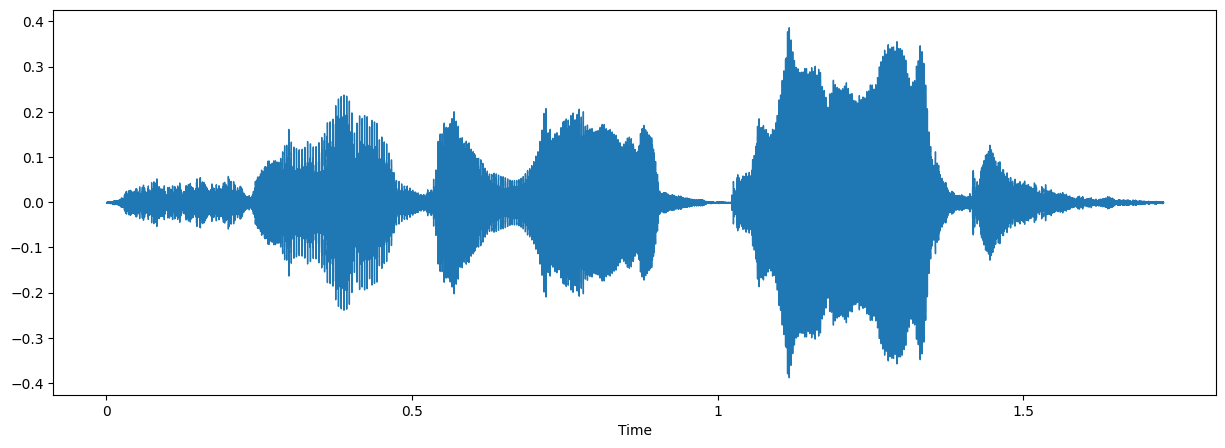

In [ ]:
# lets play a fearful track
fname = TESS + 'YAF_fear/YAF_dog_fear.wav'

data, sampling_rate = librosa.load(fname)
plt.figure(figsize=(15, 5))
librosa.display.waveshow(data, sr=sampling_rate)

# Lets play the audio
ipd.Audio(fname)

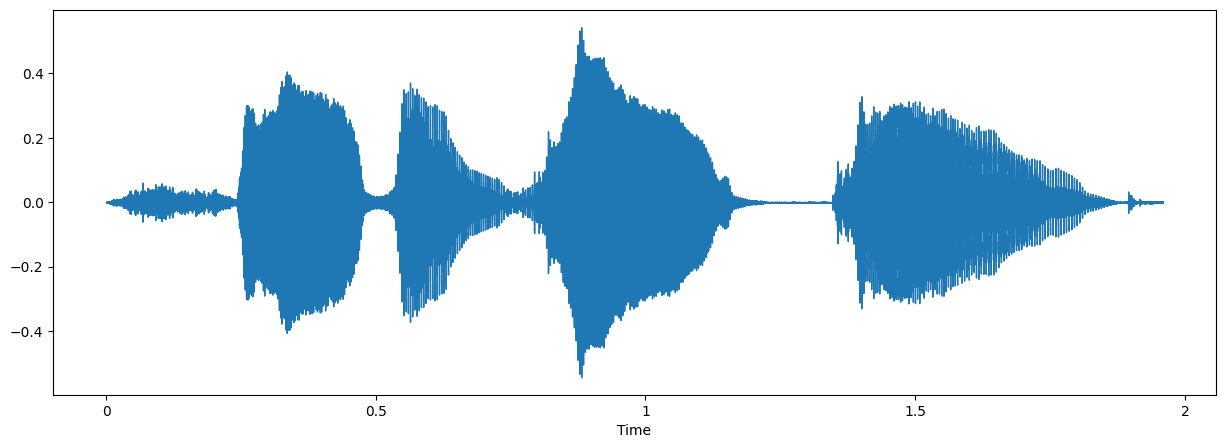

In [ ]:
# lets play a happy track
fname =  TESS + 'YAF_happy/YAF_dog_happy.wav'

data, sampling_rate = librosa.load(fname)
plt.figure(figsize=(15, 5))
librosa.display.waveshow(data, sr=sampling_rate)

# Lets play the audio
ipd.Audio(fname)

In [ ]:
EmotionData = pd.concat([SAVEE_df, RAV_df, TESS_df], axis = 0)
print(EmotionData.labels.value_counts())
#EmotionData.head()
EmotionData.to_csv("Data_path.csv",index=False)

Unknown            800
female_neutral     544
female_happy       496
female_angry       496
female_disgust     496
female_sad         296
female_fear        296
male_neutral       264
male_angry         156
male_disgust       156
male_fear          156
male_happy         156
male_sad           156
male_surprise      156
female_surprise     96
Name: labels, dtype: int64


In [ ]:
EmotionData.tail()

,labels,source,path
2795,Unknown,TESS,../../dataset/Tess/TESS_Toronto_emotional_spee...
2796,Unknown,TESS,../../dataset/Tess/TESS_Toronto_emotional_spee...
2797,Unknown,TESS,../../dataset/Tess/TESS_Toronto_emotional_spee...
2798,Unknown,TESS,../../dataset/Tess/TESS_Toronto_emotional_spee...
2799,Unknown,TESS,../../dataset/Tess/TESS_Toronto_emotional_spee...


In [ ]:
# lets pick up the meta-data that we got from our first part of the Kernel
ref = pd.read_csv("Data_path.csv")
ref.head()

,labels,source,path
0,male_angry,SAVEE,../../dataset/Savee/ALL/DC_a01.wav
1,male_angry,SAVEE,../../dataset/Savee/ALL/DC_a02.wav
2,male_angry,SAVEE,../../dataset/Savee/ALL/DC_a03.wav
3,male_angry,SAVEE,../../dataset/Savee/ALL/DC_a04.wav
4,male_angry,SAVEE,../../dataset/Savee/ALL/DC_a05.wav


**FEATURE EXTRACTION**
There are lots of features which we can get from an audio data such as
* Spectral Centroid
* Zero Crossing Rate
* Chroma Frequencies
* Mel Frequency Ceptral Coefficient(MFCC)
* Spectral Roll off
But for human voice characterization and modelling MFCC is the best feature so that's why we are using MFCC feature and extract it for each of the data.

Lets extract MFCC feature for one of the example voice

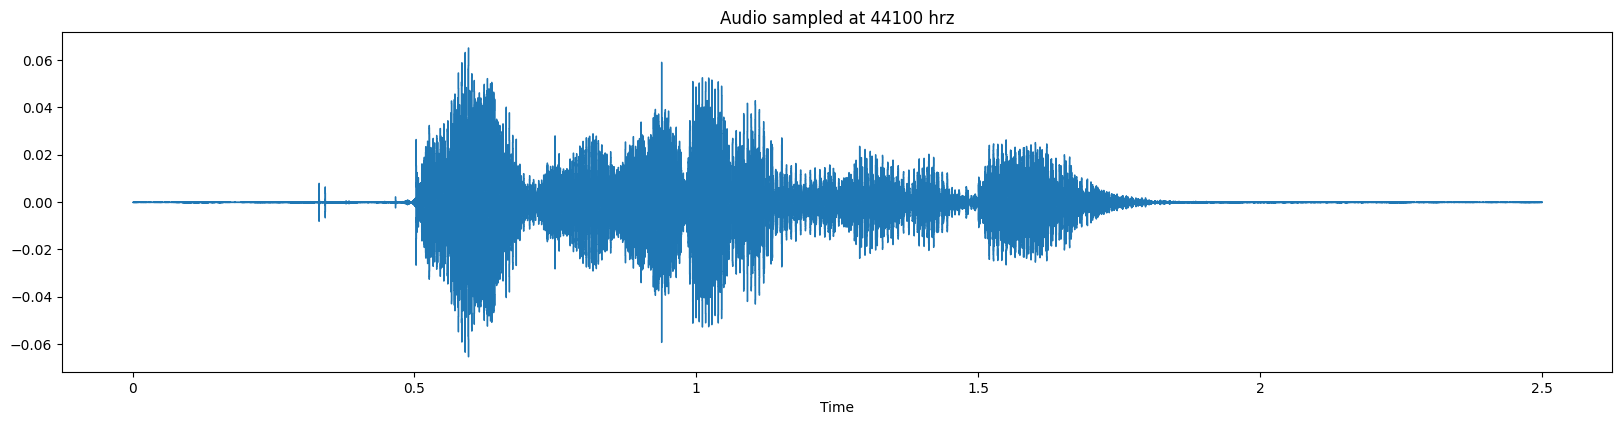

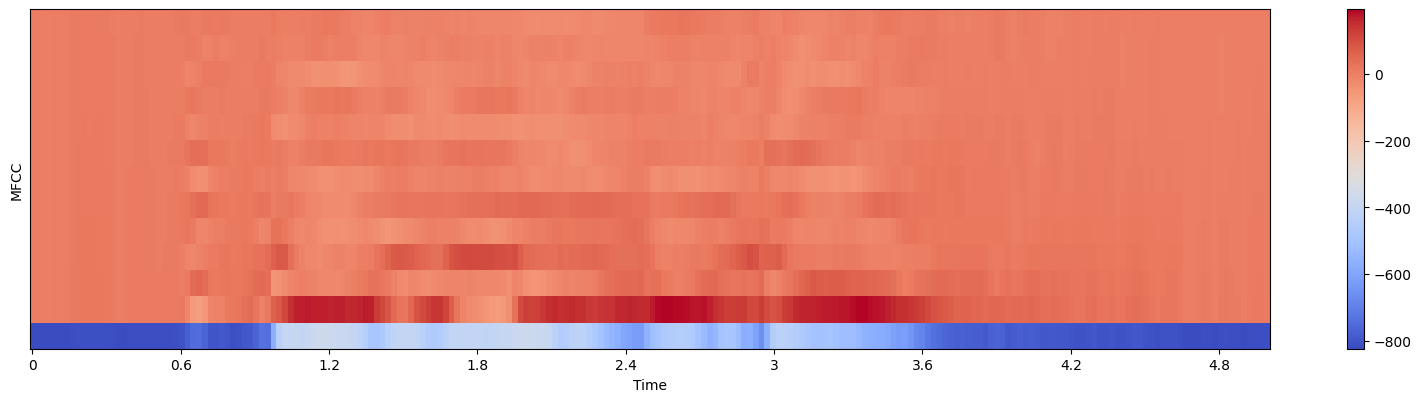

In [ ]:
# Source - RAVDESS; Gender - Male; Emotion - Happy
path = RAV+"Actor_11/03-01-03-01-02-02-11.wav"
X, sample_rate = librosa.load(path, res_type='kaiser_fast',duration=2.5,sr=22050*2,offset=0.5)
mfcc = librosa.feature.mfcc(y=X, sr=sample_rate, n_mfcc=13)

# audio wave
plt.figure(figsize=(20, 15))
plt.subplot(3,1,1)
librosa.display.waveshow(X, sr=sample_rate)
plt.title('Audio sampled at 44100 hrz')

# MFCC
plt.figure(figsize=(20, 15))
plt.subplot(3,1,1)
#Here we are displaying Spectrogram for the Happy voice and lets visualiza how its look like
librosa.display.specshow(mfcc, x_axis='time')
plt.ylabel('MFCC')
plt.colorbar()

ipd.Audio(path)

Now lets extract this feature for entire dataset and then concatinate this feature column into our dataframe

In [ ]:
df = pd.DataFrame(columns=['feature'])

# loop feature extraction over the entire dataset
counter=0
for index,path in enumerate(ref.path):
    X, sample_rate = librosa.load(path
                                  , res_type='kaiser_fast'
                                  ,duration=2.5
                                  ,sr=44100
                                  ,offset=0.5
                                 )
    sample_rate = np.array(sample_rate)

    # mean as the feature. Could do min and max etc as well.
    mfccs = np.mean(librosa.feature.mfcc(y=X,
                                        sr=sample_rate,
                                        n_mfcc=13),
                    axis=0)
    df.loc[counter] = [mfccs]
    counter=counter+1

# Check a few records to make sure its processed successfully
print(len(df))
df.head()

4720


,feature
0,"[-4.6414204, -3.8608994, -6.2191906, -5.926542..."
1,"[-8.690718, -12.522839, -22.928043, -23.243807..."
2,"[-8.814863, -12.819055, -24.178183, -23.84745,..."
3,"[-2.2684255, -4.3170776, -12.285237, -13.08302..."
4,"[-13.485307, -16.260418, -25.884357, -27.82704..."


In [ ]:
#concatinating the feature column into the complete dataframe
df = pd.concat([ref,pd.DataFrame(df['feature'].values.tolist())],axis=1)
df[:5]

,labels,source,path,0,1,2,3,4,5,6,...,206,207,208,209,210,211,212,213,214,215
0,male_angry,SAVEE,../../dataset/Savee/ALL/DC_a01.wav,-4.641420,-3.860899,-6.219191,-5.926542,-5.850418,-4.808961,-2.513002,...,-4.088851,-5.023864,-5.254714,-5.234093,-5.310307,-5.621666,-6.072197,-6.611348,-3.999875,1.390506
1,male_angry,SAVEE,../../dataset/Savee/ALL/DC_a02.wav,-8.690718,-12.522839,-22.928043,-23.243807,-22.926605,-23.432241,-14.830006,...,-22.627258,-22.633406,-22.511597,-24.300154,-24.496809,-22.895985,-23.511505,-24.342152,-16.465857,-8.936036
2,male_angry,SAVEE,../../dataset/Savee/ALL/DC_a03.wav,-8.814863,-12.819055,-24.178183,-23.847450,-15.182783,-10.732485,-8.681472,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,male_angry,SAVEE,../../dataset/Savee/ALL/DC_a04.wav,-2.268425,-4.317078,-12.285237,-13.083024,-12.041326,-11.819769,-9.414148,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,male_angry,SAVEE,../../dataset/Savee/ALL/DC_a05.wav,-13.485307,-16.260418,-25.884357,-27.827044,-27.593534,-26.666508,-18.659023,...,-25.291666,-25.854906,-26.821354,-25.436455,-24.179941,-23.281618,-24.167494,-25.228062,-20.599659,-15.929615


In [ ]:
# replace NA with 0
df=df.fillna(0)
print(df.shape)
df[:5]

(4720, 219)


,labels,source,path,0,1,2,3,4,5,6,...,206,207,208,209,210,211,212,213,214,215
0,male_angry,SAVEE,../../dataset/Savee/ALL/DC_a01.wav,-4.641420,-3.860899,-6.219191,-5.926542,-5.850418,-4.808961,-2.513002,...,-4.088851,-5.023864,-5.254714,-5.234093,-5.310307,-5.621666,-6.072197,-6.611348,-3.999875,1.390506
1,male_angry,SAVEE,../../dataset/Savee/ALL/DC_a02.wav,-8.690718,-12.522839,-22.928043,-23.243807,-22.926605,-23.432241,-14.830006,...,-22.627258,-22.633406,-22.511597,-24.300154,-24.496809,-22.895985,-23.511505,-24.342152,-16.465857,-8.936036
2,male_angry,SAVEE,../../dataset/Savee/ALL/DC_a03.wav,-8.814863,-12.819055,-24.178183,-23.847450,-15.182783,-10.732485,-8.681472,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
3,male_angry,SAVEE,../../dataset/Savee/ALL/DC_a04.wav,-2.268425,-4.317078,-12.285237,-13.083024,-12.041326,-11.819769,-9.414148,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
4,male_angry,SAVEE,../../dataset/Savee/ALL/DC_a05.wav,-13.485307,-16.260418,-25.884357,-27.827044,-27.593534,-26.666508,-18.659023,...,-25.291666,-25.854906,-26.821354,-25.436455,-24.179941,-23.281618,-24.167494,-25.228062,-20.599659,-15.929615


In [ ]:
from sklearn.model_selection import train_test_split

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(df.drop(['path','labels','source'],axis=1)
                                                    , df.labels
                                                    , test_size=0.25
                                                    , shuffle=True
                                                    , random_state=42
                                                   )

# Lets see how the data present itself before normalisation
X_train[150:160]

,0,1,2,3,4,5,6,7,8,9,...,206,207,208,209,210,211,212,213,214,215
4586,-14.420523,-19.253880,-33.457912,-35.388756,-33.537430,-32.625786,-27.731255,-24.263987,-27.220287,-33.363426,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
1022,-51.030926,-47.310570,-47.529602,-49.782688,-49.140648,-48.633381,-49.743210,-50.517647,-50.466434,-50.296623,...,-41.190159,-42.330181,-42.728001,-43.271709,-43.538982,-43.374249,-44.041397,-47.678623,-50.496437,-50.108772
3733,-11.888713,-14.575375,-23.065907,-21.002321,-16.493801,-12.914961,-8.373713,-5.781566,-7.315705,-9.684256,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
4612,-25.266222,-27.553782,-26.445839,-29.697365,-33.370888,-33.512154,-33.437466,-32.109589,-31.376474,-33.223579,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
2677,-17.993330,-21.421581,-25.650648,-23.356699,-24.337349,-24.219807,-25.164778,-24.693085,-23.932333,-23.769148,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
2830,-19.373587,-20.360760,-26.664730,-27.693624,-27.300232,-27.349770,-27.191433,-27.833006,-27.715748,-30.075624,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
1662,-41.200371,-41.200371,-41.200371,-41.200371,-41.200371,-41.200371,-41.200371,-41.200371,-41.194736,-41.200371,...,-40.320107,-40.826057,-40.975559,-41.166569,-41.184006,-41.200371,-41.200371,-41.200371,-41.200371,-41.200371
665,-68.243706,-68.243706,-68.243706,-68.243706,-68.243706,-68.243706,-68.243706,-68.243706,-67.374611,-66.573479,...,-51.560909,-51.003139,-51.680172,-52.301521,-51.118233,-54.838196,-54.941746,-54.536983,-56.650700,-56.095642
3528,-17.366819,-21.038504,-26.873802,-29.434935,-30.111677,-30.657267,-30.811232,-32.781796,-32.786892,-33.727280,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
4252,-21.007030,-20.814360,-25.850586,-25.565228,-24.620083,-24.264626,-25.833384,-25.735861,-26.117771,-25.317972,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000


In [ ]:
# Lets do data normalization
#Here we are using z-score normalization technique
mean = np.mean(X_train, axis=0)
std = np.std(X_train, axis=0)

X_train = (X_train - mean)/std
X_test = (X_test - mean)/std

# Check the dataset now
X_train[150:160]
print(mean, std)

[[[-6.93667849e+02]
  [-6.88874488e+02]
  [-6.87095694e+02]
  ...
  [-7.23164491e+02]
  [-7.23164491e+02]
  [-7.23164491e+02]]

 [[ 1.56145822e+01]
  [ 1.78634547e+01]
  [ 1.82299376e+01]
  ...
  [ 0.00000000e+00]
  [ 0.00000000e+00]
  [ 0.00000000e+00]]

 [[ 1.89569239e+00]
  [ 1.10373063e+00]
  [ 2.55316425e-01]
  ...
  [ 0.00000000e+00]
  [ 0.00000000e+00]
  [ 0.00000000e+00]]

 ...

 [[ 5.33782127e-01]
  [ 5.95434431e-01]
  [ 3.99153569e-01]
  ...
  [ 0.00000000e+00]
  [ 0.00000000e+00]
  [ 0.00000000e+00]]

 [[ 4.72670461e-01]
  [ 5.99455399e-01]
  [ 5.81414124e-01]
  ...
  [ 0.00000000e+00]
  [ 0.00000000e+00]
  [ 0.00000000e+00]]

 [[ 4.08699324e-01]
  [ 4.65436235e-01]
  [ 3.86067170e-01]
  ...
  [ 0.00000000e+00]
  [ 0.00000000e+00]
  [ 0.00000000e+00]]] [[[139.03294056]
  [140.47304573]
  [140.22104079]
  ...
  [ 99.34287932]
  [ 99.34287932]
  [ 99.34287932]]

 [[ 39.40921483]
  [ 42.91941744]
  [ 44.1149954 ]
  ...
  [  0.        ]
  [  0.        ]
  [  0.        ]]

 [[ 11

In [ ]:
from keras.utils import to_categorical
from sklearn.preprocessing import LabelEncoder
import pickle


In [ ]:
import numpy as np
from sklearn.preprocessing import LabelEncoder
from keras.utils import to_categorical
import pickle

X_train = np.array(X_train)
y_train = np.array(y_train)
X_test = np.array(X_test)
y_test = np.array(y_test)

# Label encode the target
lb = LabelEncoder()
y_train = to_categorical(lb.fit_transform(y_train))
y_test = to_categorical(lb.fit_transform(y_test))

print(X_train.shape)
print(lb.classes_)
# print(y_train[0:10])
# print(y_test[0:10])

# Pickle the lb object for future use
filename = 'labels'
outfile = open(filename, 'wb')
pickle.dump(lb, outfile)
outfile.close()


(3540, 216)
['Unknown' 'female_angry' 'female_disgust' 'female_fear' 'female_happy'
 'female_neutral' 'female_sad' 'female_surprise' 'male_angry'
 'male_disgust' 'male_fear' 'male_happy' 'male_neutral' 'male_sad'
 'male_surprise']


In [ ]:
X_train = np.expand_dims(X_train, axis=2)
X_test = np.expand_dims(X_test, axis=2)
X_train.shape

(3540, 216, 1)

In [ ]:


import tensorflow as tf
from tensorflow.keras import regularizers
from tensorflow.keras.preprocessing import sequence
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential, Model, model_from_json
from tensorflow.keras.layers import Dense, Embedding, LSTM
from tensorflow.keras.layers import Input, Flatten, Dropout, Activation, BatchNormalization
from tensorflow.keras.layers import Conv1D, MaxPooling1D, AveragePooling1D
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.callbacks import ModelCheckpoint


In [ ]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Embedding, LSTM, Conv1D, MaxPooling1D, Flatten, Dropout, Activation, BatchNormalization
from tensorflow.keras.optimizers import Adam

model = Sequential()
model.add(Conv1D(256, 8, padding='same', input_shape=(X_train.shape[1], 1)))  # Assuming X_train is defined
model.add(Activation('relu'))
model.add(Conv1D(256, 8, padding='same'))
model.add(BatchNormalization())
model.add(Activation('relu'))
model.add(Dropout(0.25))
model.add(MaxPooling1D(pool_size=8))
model.add(Conv1D(128, 8, padding='same'))
model.add(Activation('relu'))
model.add(Conv1D(128, 8, padding='same'))
model.add(Activation('relu'))
model.add(Conv1D(128, 8, padding='same'))
model.add(Activation('relu'))
model.add(Conv1D(128, 8, padding='same'))
model.add(BatchNormalization())
model.add(Activation('relu'))
model.add(Dropout(0.25))
model.add(MaxPooling1D(pool_size=8))
model.add(Conv1D(64, 8, padding='same'))
model.add(Activation('relu'))
model.add(Conv1D(64, 8, padding='same'))
model.add(Activation('relu'))
model.add(Flatten())
model.add(Dense(15, activation='softmax'))  # Corrected to 15 classes

# Compile the model
opt = Adam(learning_rate=0.0001)
model.compile(loss='categorical_crossentropy', optimizer=opt, metrics=['accuracy'])

# Print model summary
model.summary()


Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d_40 (Conv1D)              │ (None, 216, 256)       │         2,304 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_43 (Activation)      │ (None, 216, 256)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_41 (Conv1D)              │ (None, 216, 256)       │       524,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_10          │ (None, 216, 256)       │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_44 (Activation)      │ (None, 216, 256)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_10 (Dropout)            │ (None, 216, 256)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_10 (MaxPooling1D) │ (None, 27, 256)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_42 (Conv1D)              │ (None, 27, 128)        │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_45 (Activation)      │ (None, 27, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_43 (Conv1D)              │ (None, 27, 128)        │       131,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_46 (Activation)      │ (None, 27, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_44 (Conv1D)              │ (None, 27, 128)        │       131,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_47 (Activation)      │ (None, 27, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_45 (Conv1D)              │ (None, 27, 128)        │       131,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_11          │ (None, 27, 128)        │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_48 (Activation)      │ (None, 27, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_11 (Dropout)            │ (None, 27, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_11 (MaxPooling1D) │ (None, 3, 128)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_46 (Conv1D)              │ (None, 3, 64)          │        65,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_49 (Activation)      │ (None, 3, 64)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_47 (Conv1D)              │ (None, 3, 64)          │        32,832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_50 (Activation)      │ (None, 3, 64)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_5 (Flatten)             │ (None, 192)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 15)             │         2,89

 Total params: 1,285,583 (4.90 MB)

 Trainable params: 1,284,815 (4.90 MB)

 Non-trainable params: 768 (3.00 KB)

In [ ]:
model.compile(loss='categorical_crossentropy', optimizer=opt,metrics=['accuracy'])
model_history=model.fit(X_train, y_train, batch_size=10, epochs=75, validation_data=(X_test, y_test))

Epoch 1/75
354/354 ━━━━━━━━━━━━━━━━━━━━ 26s 64ms/step - accuracy: 0.2731 - loss: 2.1616 - val_accuracy: 0.3203 - val_loss: 2.2082
Epoch 2/75
354/354 ━━━━━━━━━━━━━━━━━━━━ 27s 76ms/step - accuracy: 0.5154 - loss: 1.3912 - val_accuracy: 0.5822 - val_loss: 1.4489
Epoch 3/75
354/354 ━━━━━━━━━━━━━━━━━━━━ 26s 73ms/step - accuracy: 0.6152 - loss: 1.1242 - val_accuracy: 0.6110 - val_loss: 1.2256
Epoch 4/75
354/354 ━━━━━━━━━━━━━━━━━━━━ 28s 78ms/step - accuracy: 0.6551 - loss: 0.9620 - val_accuracy: 0.6305 - val_loss: 1.1382
Epoch 5/75
354/354 ━━━━━━━━━━━━━━━━━━━━ 26s 74ms/step - accuracy: 0.6791 - loss: 0.9101 - val_accuracy: 0.6102 - val_loss: 1.1270
Epoch 6/75
354/354 ━━━━━━━━━━━━━━━━━━━━ 29s 82ms/step - accuracy: 0.6908 - loss: 0.8706 - val_accuracy: 0.6678 - val_loss: 1.0103
Epoch 7/75
354/354 ━━━━━━━━━━━━━━━━━━━━ 31s 89ms/step - accuracy: 0.7239 - loss: 0.7973 - val_accuracy: 0.6695 - val_loss: 0.9959
Epoch 8/75
354/354 ━━━━━━━━━━━━━━━━━━━━ 31s 89ms/step - accuracy: 0.7447 - loss: 0.7176 - 

In [ ]:

num_classes = np.unique(y_train).size
print("Number of classes:", num_classes)


Number of classes: 2


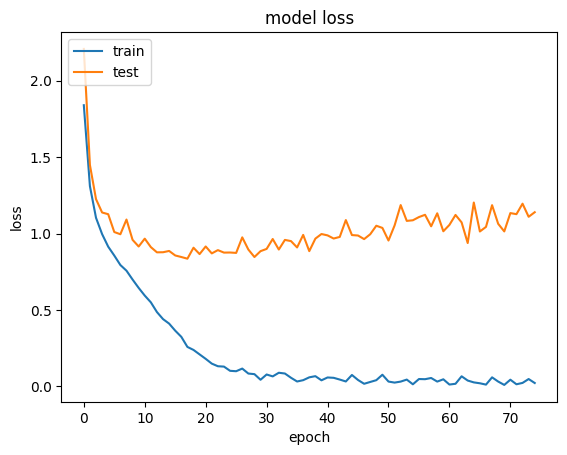

In [ ]:
plt.plot(model_history.history['loss'])
plt.plot(model_history.history['val_loss'])
plt.title('model loss')
plt.ylabel('loss')
plt.xlabel('epoch')
plt.legend(['train', 'test'], loc='upper left')
plt.show()

**Observation**

Here we found that Accuracy is arround 0.9901 and loss is 0.0291
But When we look around Validation set we found that val_loss: 1.0878  val_acc: 0.7398
Which signifies the overfitting as val_loss>train_loss

**To reduche the overfitting**
We require to improve the dataset: For that we will use data augmentation
Next we will use 2D convNet or any other model to train our data

In [ ]:
# Save model and weights
model_name = 'Emotion_Model.h5'
save_dir = os.path.join(os.getcwd(), 'saved_models')

if not os.path.isdir(save_dir):
    os.makedirs(save_dir)
model_path = os.path.join(save_dir, model_name)
model.save(model_path)
print('Save model and weights at %s ' % model_path)

# Save the model to disk
model_json = model.to_json()
with open("model_json.json", "w") as json_file:
    json_file.write(model_json)

Save model and weights at c:\Users\khan\Desktop\Faisal_FYP\new_model\Testin\saved_models\Emotion_Model.h5 


In [ ]:
import tensorflow as tf
from tensorflow.keras.models import model_from_json

# loading json and model architecture
json_file = open('model_json.json', 'r')
loaded_model_json = json_file.read()
json_file.close()
loaded_model = model_from_json(loaded_model_json)

# load weights into new model
loaded_model.load_weights("saved_models/Emotion_Model.h5")
print("Loaded model from disk")

# Keras optimizer with updated argument
opt = tf.keras.optimizers.Adam(learning_rate=0.0001)
loaded_model.compile(loss='categorical_crossentropy', optimizer=opt, metrics=['accuracy'])

# Evaluate the model
score = loaded_model.evaluate(X_test, y_test, verbose=0)
print("%s: %.2f%%" % (loaded_model.metrics_names[1], score[1]*100))


Loaded model from disk
compile_metrics: 72.71%


In [ ]:
preds = loaded_model.predict(X_test,
                         batch_size=10,
                         verbose=1)

preds=preds.argmax(axis=1)
preds

118/118 ━━━━━━━━━━━━━━━━━━━━ 2s 15ms/step


array([0, 6, 9, ..., 0, 0, 1], dtype=int64)

In [ ]:
# predictions
preds = preds.astype(int).flatten()
preds = (lb.inverse_transform((preds)))
preds = pd.DataFrame({'predictedvalues': preds})

# Actual labels
actual=y_test.argmax(axis=1)
actual = actual.astype(int).flatten()
actual = (lb.inverse_transform((actual)))
actual = pd.DataFrame({'actualvalues': actual})

# Lets combined both of them into a single dataframe
finaldf = actual.join(preds)
finaldf.head()

,actualvalues,predictedvalues
0,Unknown,Unknown
1,female_sad,female_sad
2,male_neutral,male_disgust
3,male_surprise,female_disgust
4,female_happy,female_happy


In [ ]:
finaldf.to_csv('Predictions.csv', index=False)
finaldf.groupby('predictedvalues').count()

,actualvalues
predictedvalues,
Unknown,210
female_angry,140
female_disgust,113
female_fear,77
female_happy,126
female_neutral,131
female_sad,84
female_surprise,25
male_angry,46


In [ ]:
from sklearn.metrics import confusion_matrix, accuracy_score, classification_report

In [ ]:
classes = finaldf.actualvalues.unique()
classes.sort()
print(classification_report(finaldf.actualvalues, finaldf.predictedvalues, target_names=classes))

                 precision    recall  f1-score   support

        Unknown       0.93      0.95      0.94       207
   female_angry       0.80      0.86      0.83       130
 female_disgust       0.88      0.82      0.85       122
    female_fear       0.69      0.88      0.77        60
   female_happy       0.89      0.85      0.87       131
 female_neutral       0.82      0.88      0.85       122
     female_sad       0.71      0.77      0.74        78
female_surprise       0.76      0.73      0.75        26
     male_angry       0.35      0.42      0.38        38
   male_disgust       0.48      0.48      0.48        33
      male_fear       0.30      0.43      0.36        44
     male_happy       0.16      0.13      0.14        39
   male_neutral       0.61      0.42      0.50        65
       male_sad       0.29      0.22      0.25        41
  male_surprise       0.28      0.16      0.20        44

       accuracy                           0.73      1180
      macro avg       0.60   

In [ ]:
import seaborn as sns

In [ ]:
def print_confusion_matrix(confusion_matrix, class_names, figsize = (10,7), fontsize=14):
    df_cm = pd.DataFrame(
        confusion_matrix, index=class_names, columns=class_names,
    )
    fig = plt.figure(figsize=figsize)
    try:
        heatmap = sns.heatmap(df_cm, annot=True, fmt="d")
    except ValueError:
        raise ValueError("Confusion matrix values must be integers.")

    heatmap.yaxis.set_ticklabels(heatmap.yaxis.get_ticklabels(), rotation=0, ha='right', fontsize=fontsize)
    heatmap.xaxis.set_ticklabels(heatmap.xaxis.get_ticklabels(), rotation=45, ha='right', fontsize=fontsize)
    plt.ylabel('True label')
    plt.xlabel('Predicted label')

# Gender recode function
def gender(row):
    if row == 'female_disgust' or 'female_fear' or 'female_happy' or 'female_sad' or 'female_surprise' or 'female_neutral':
        return 'female'
    elif row == 'male_angry' or 'male_fear' or 'male_happy' or 'male_sad' or 'male_surprise' or 'male_neutral' or 'male_disgust':
        return 'male'

0.7271186440677966


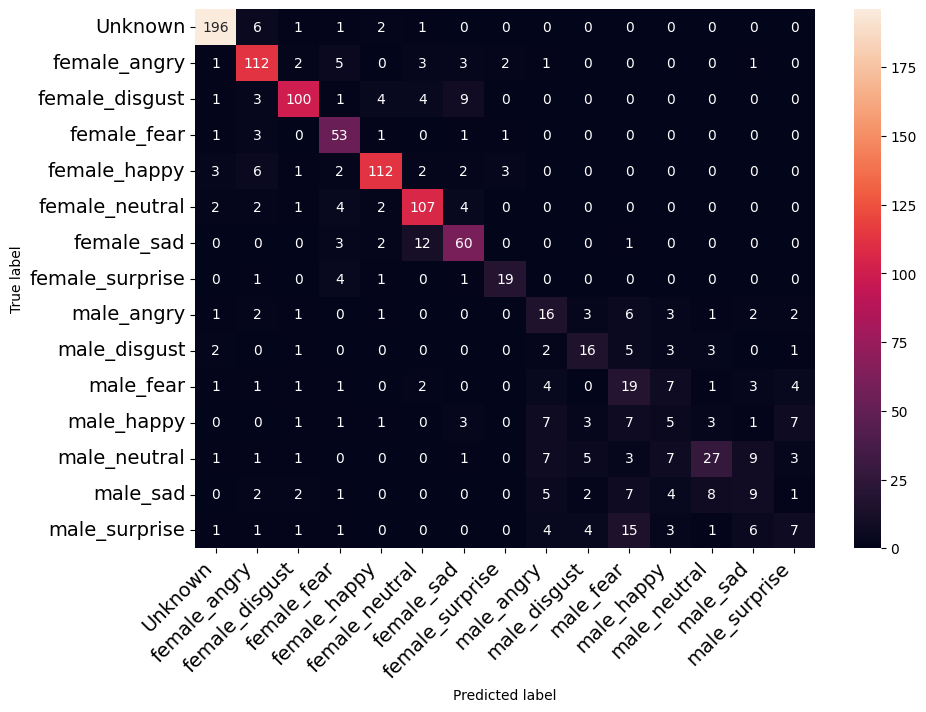

In [ ]:
# Get the predictions file
finaldf = pd.read_csv("Predictions.csv")
classes = finaldf.actualvalues.unique()
classes.sort()

# Confusion matrix
c = confusion_matrix(finaldf.actualvalues, finaldf.predictedvalues)
print(accuracy_score(finaldf.actualvalues, finaldf.predictedvalues))
print_confusion_matrix(c, class_names = classes)

Now let's see how we can reduce the wrong prediction i.e False Positive and False Negatives

# Data Augmentation
Lets add augmented data to our Dataset
Before proceeding lets understand some of the datasets

In [ ]:
# Augmentation methods
#########################
def noise(data):
    """
    Adding White Noise.
    """
    # you can take any distribution from https://docs.scipy.org/doc/numpy-1.13.0/reference/routines.random.html
    noise_amp = 0.05*np.random.uniform()*np.amax(data)   # more noise reduce the value to 0.5
    data = data.astype('float64') + noise_amp * np.random.normal(size=data.shape[0])
    return data

def shift(data):
    """
    Random Shifting.
    """
    s_range = int(np.random.uniform(low=-5, high = 5)*1000)  #default at 500
    return np.roll(data, s_range)

def stretch(data, rate=0.8):
    """
    Streching the Sound. Note that this expands the dataset slightly
    """
    data = librosa.effects.time_stretch(data, rate)
    return data

def pitch(data, sample_rate):
    """
    Pitch Tuning.
    """
    bins_per_octave = 12
    pitch_pm = 2
    pitch_change =  pitch_pm * 2*(np.random.uniform())
    data = librosa.effects.pitch_shift(data.astype('float64'),
                                      sample_rate, n_steps=pitch_change,
                                      bins_per_octave=bins_per_octave)
    return data

def dyn_change(data):
    """
    Random Value Change.
    """
    dyn_change = np.random.uniform(low=-0.5 ,high=7)  # default low = 1.5, high = 3
    return (data * dyn_change)

def speedNpitch(data):
    """
    peed and Pitch Tuning.
    """
    # you can change low and high here
    length_change = np.random.uniform(low=0.8, high = 1)
    speed_fac = 1.2  / length_change # try changing 1.0 to 2.0 ... =D
    tmp = np.interp(np.arange(0,len(data),speed_fac),np.arange(0,len(data)),data)
    minlen = min(data.shape[0], tmp.shape[0])
    data *= 0
    data[0:minlen] = tmp[0:minlen]
    return data


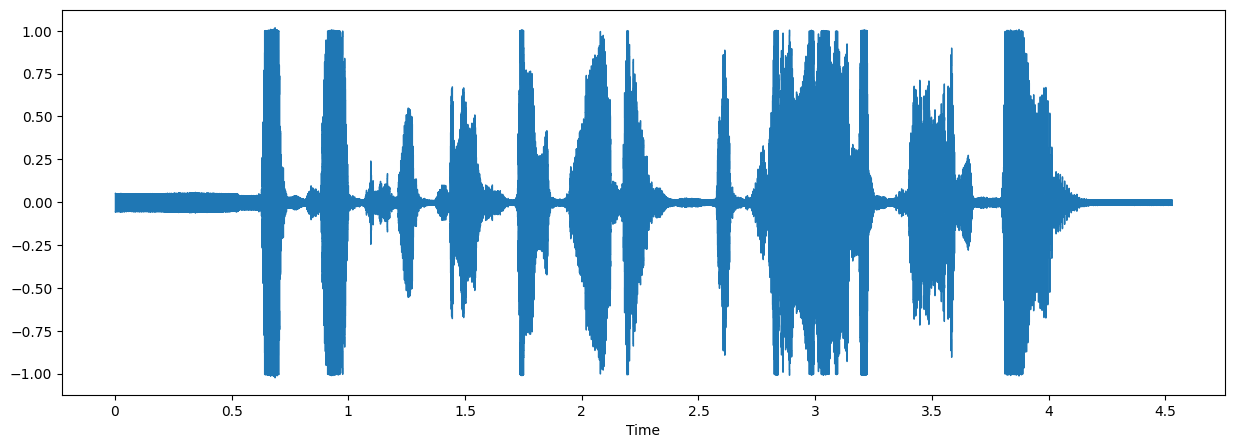

In [ ]:
# Use one audio file in previous parts again
fname = SAVEE+'JK_f11.wav'
data, sampling_rate = librosa.load(fname)
plt.figure(figsize=(15, 5))
librosa.display.waveshow(data, sr=sampling_rate)

# Play it again to refresh our memory
ipd.Audio(data, rate=sampling_rate)

Now add some augmentation into the voice

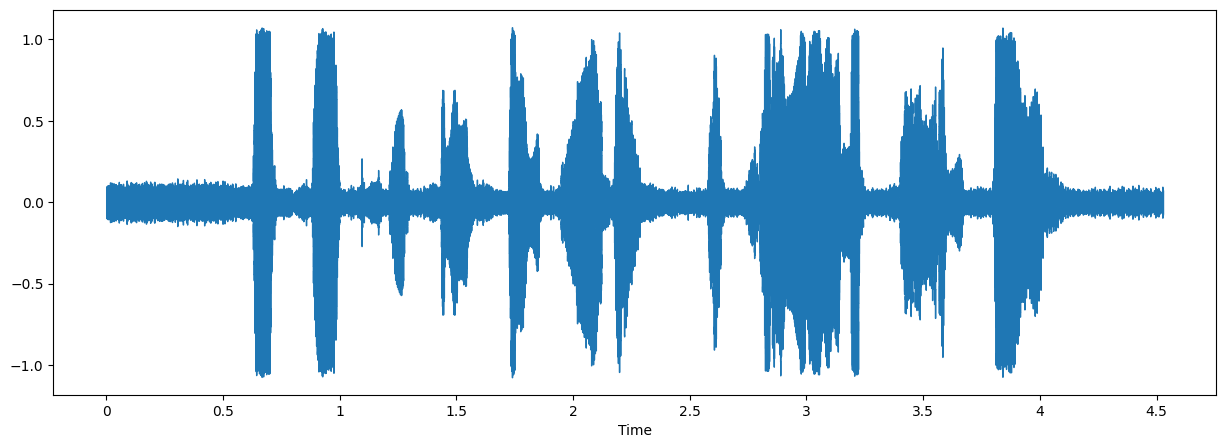

In [ ]:
#Static Noise
x = noise(data)
plt.figure(figsize=(15, 5))
librosa.display.waveshow(x, sr=sampling_rate)
ipd.Audio(x, rate=sampling_rate)

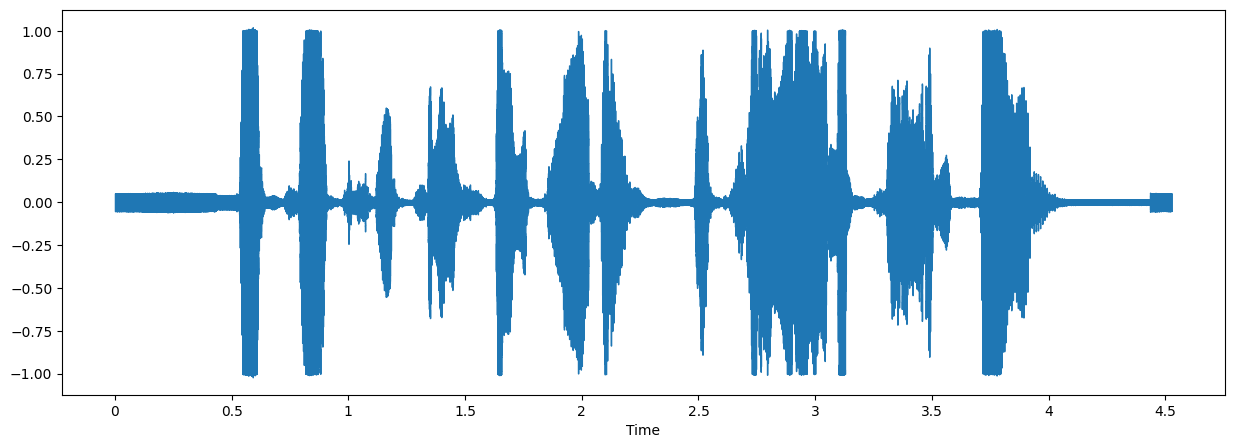

In [ ]:
#shift: It basically add more time and shift the voice a little bit
x = shift(data)
plt.figure(figsize=(15, 5))
librosa.display.waveshow(x, sr=sampling_rate)
ipd.Audio(x, rate=sampling_rate)

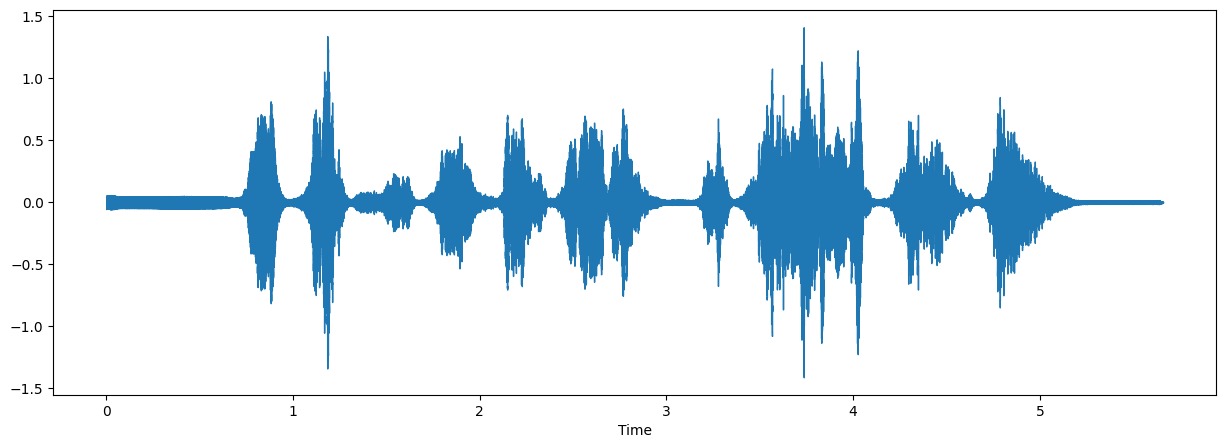

In [ ]:
#Stretch: It basically slow down the speaking time
import librosa

def stretch(data, rate=0.8):
    """
    Stretch the audio data by a specified rate. A rate less than 1.0 slows down the audio,
    a rate greater than 1.0 speeds it up.
    """
    stretched_data = librosa.effects.time_stretch(data, rate=rate)
    return stretched_data
import matplotlib.pyplot as plt
import IPython.display as ipd
import librosa.display

# Assuming 'data' and 'sampling_rate' are already defined
x = stretch(data, rate=0.8)  # Slow down the audio
plt.figure(figsize=(15, 5))
librosa.display.waveshow(x, sr=sampling_rate)
audio_playback = ipd.Audio(x, rate=sampling_rate)


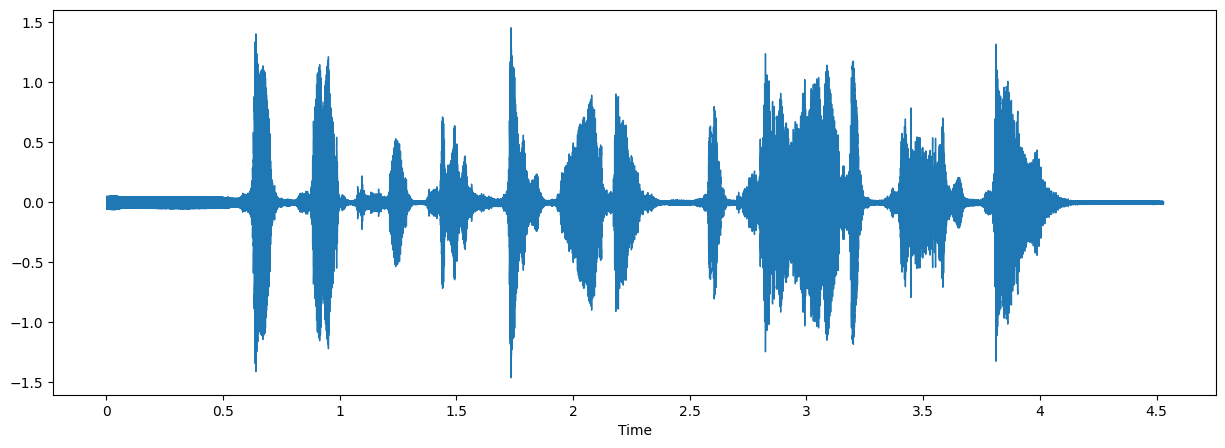

In [ ]:
def pitch(data, sample_rate):
    """
    Pitch Tuning.
    """
    bins_per_octave = 12
    pitch_pm = 2
    pitch_change = pitch_pm * 2 * (np.random.uniform())
    return librosa.effects.pitch_shift(data.astype('float64'),
                                       sr=sample_rate,
                                       n_steps=pitch_change,
                                       bins_per_octave=bins_per_octave)
import matplotlib.pyplot as plt
import IPython.display as ipd
import librosa.display
import numpy as np
import librosa

# Assume 'data' and 'sampling_rate' are already defined
x = pitch(data, sampling_rate)
plt.figure(figsize=(15, 5))
librosa.display.waveshow(x, sr=sampling_rate)
audio_playback = ipd.Audio(x, rate=sampling_rate)


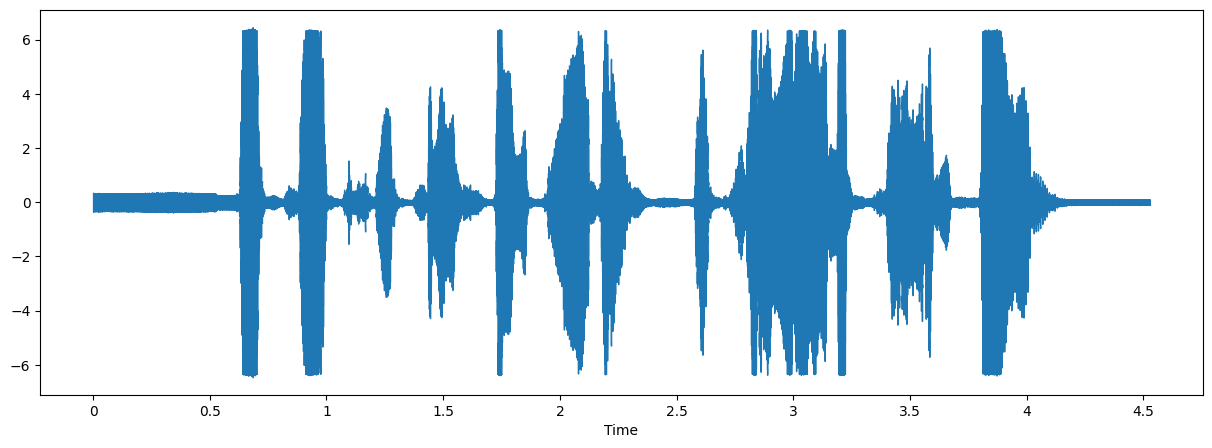

In [ ]:
#Dynamic Change
x = dyn_change(data)
plt.figure(figsize=(15, 5))
librosa.display.waveshow(x, sr=sampling_rate)
ipd.Audio(x, rate=sampling_rate)

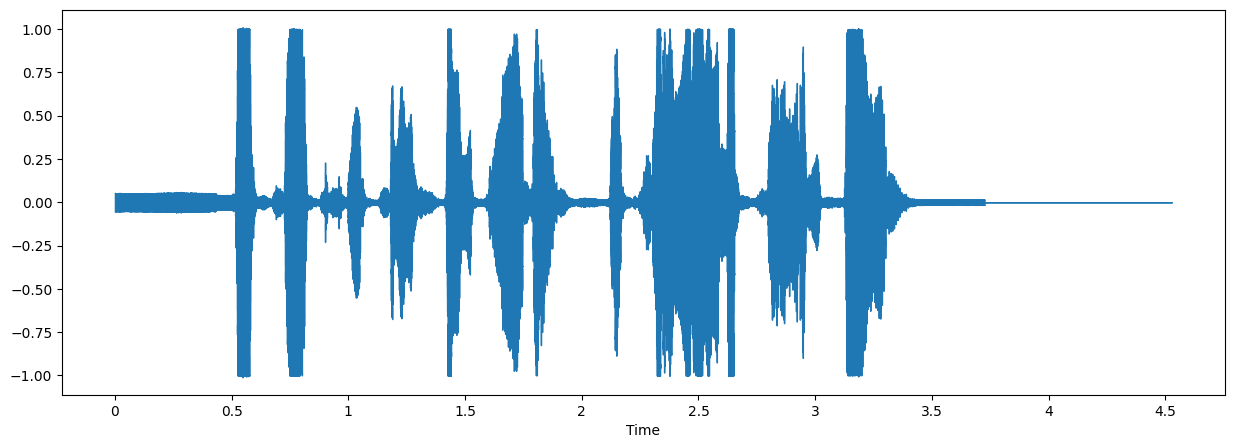

In [ ]:
#Speed and Pitch: This one is basically the combination of both speed and pitch
x = speedNpitch(data)
plt.figure(figsize=(15, 5))
librosa.display.waveshow(x, sr=sampling_rate)
ipd.Audio(x, rate=sampling_rate)

In [ ]:
#Now choosing our meta data and augment the voice into the whole datasets
ref.head()

,labels,source,path
0,male_angry,SAVEE,../../dataset/Savee/ALL/DC_a01.wav
1,male_angry,SAVEE,../../dataset/Savee/ALL/DC_a02.wav
2,male_angry,SAVEE,../../dataset/Savee/ALL/DC_a03.wav
3,male_angry,SAVEE,../../dataset/Savee/ALL/DC_a04.wav
4,male_angry,SAVEE,../../dataset/Savee/ALL/DC_a05.wav


I am going to use Stretch and Dynamic change as other methods may reduce the accuracy.
If we add pitch or speed and pitch it will change the voice quality and seems like a female is taking althoug its a male's voice.

In [ ]:
from tqdm import tqdm

In [ ]:
# Note this takes a couple of minutes (~16 mins) as we're iterating over 4 datasets, and with augmentation
df = pd.DataFrame(columns=['feature'])
df_dyn_change = pd.DataFrame(columns=['feature'])
df_stretch = pd.DataFrame(columns=['feature'])
cnt = 0

# loop feature extraction over the entire dataset
for i in tqdm(ref.path):

    # first load the audio
    X, sample_rate = librosa.load(i
                                  , res_type='kaiser_fast'
                                  ,duration=2.5
                                  ,sr=44100
                                  ,offset=0.5
                                 )

    # take mfcc and mean as the feature. Could do min and max etc as well.
    mfccs = np.mean(librosa.feature.mfcc(y=X,
                                        sr=np.array(sample_rate),
                                        n_mfcc=13),
                    axis=0)

    df.loc[cnt] = [mfccs]


    # dyn_change
    aug = dyn_change(X)
    aug = np.mean(librosa.feature.mfcc(y=aug,
                                    sr=np.array(sample_rate),
                                    n_mfcc=13),
                  axis=0)
    df_dyn_change.loc[cnt] = [aug]

    # stretch
    aug = stretch(X)
    aug = np.mean(librosa.feature.mfcc(y=aug,
                                    sr=np.array(sample_rate),
                                    n_mfcc=13),
                  axis=0)
    df_stretch.loc[cnt] = [aug]

    cnt += 1

df.head()

100%|██████████| 4720/4720 [07:37<00:00, 10.32it/s]


,feature
0,"[-4.6414204, -3.8608994, -6.2191906, -5.926542..."
1,"[-8.690718, -12.522839, -22.928043, -23.243807..."
2,"[-8.814863, -12.819055, -24.178183, -23.84745,..."
3,"[-2.2684255, -4.3170776, -12.285237, -13.08302..."
4,"[-13.485307, -16.260418, -25.884357, -27.82704..."


In [ ]:
#Combining the feature to the dataset
df = pd.concat([ref,pd.DataFrame(df['feature'].values.tolist())],axis=1)
df_dyn_change = pd.concat([ref,pd.DataFrame(df_dyn_change['feature'].values.tolist())],axis=1)
df_stretch = pd.concat([ref,pd.DataFrame(df_stretch['feature'].values.tolist())],axis=1)
print(df.shape,df_dyn_change.shape,df_stretch.shape)

(4720, 219) (4720, 219) (4720, 273)


In [ ]:
df = pd.concat([df,df_dyn_change,df_stretch],axis=0,sort=False)
df=df.fillna(0)
del df_dyn_change,df_stretch

df.head()

,labels,source,path,0,1,2,3,4,5,6,...,260,261,262,263,264,265,266,267,268,269
0,male_angry,SAVEE,../../dataset/Savee/ALL/DC_a01.wav,-4.641420,-3.860899,-6.219191,-5.926542,-5.850418,-4.808961,-2.513002,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,male_angry,SAVEE,../../dataset/Savee/ALL/DC_a02.wav,-8.690718,-12.522839,-22.928043,-23.243807,-22.926605,-23.432241,-14.830006,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,male_angry,SAVEE,../../dataset/Savee/ALL/DC_a03.wav,-8.814863,-12.819055,-24.178183,-23.847450,-15.182783,-10.732485,-8.681472,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,male_angry,SAVEE,../../dataset/Savee/ALL/DC_a04.wav,-2.268425,-4.317078,-12.285237,-13.083024,-12.041326,-11.819769,-9.414148,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,male_angry,SAVEE,../../dataset/Savee/ALL/DC_a05.wav,-13.485307,-16.260418,-25.884357,-27.827044,-27.593534,-26.666508,-18.659023,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [ ]:
# Split between train and test
X_train, X_test, y_train, y_test = train_test_split(df.drop(['path','labels','source'],axis=1)
                                                    , df.labels
                                                    , test_size=0.25
                                                    , shuffle=True
                                                    , random_state=42
                                                   )

# Lets see how the data present itself before normalisation
X_train[150:160]

,0,1,2,3,4,5,6,7,8,9,...,260,261,262,263,264,265,266,267,268,269
3153,-19.541645,-20.379051,-24.215433,-24.474943,-24.779564,-24.805613,-25.089375,-26.140713,-26.308105,-25.805357,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
1406,-60.857613,-57.876385,-59.973637,-61.480099,-61.480099,-61.480099,-61.480099,-61.480099,-60.477707,-57.440956,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
3863,-10.193589,-13.950341,-21.622465,-21.906605,-22.530210,-24.810791,-28.803204,-27.488268,-24.164238,-22.119516,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
3076,-22.152742,-23.584623,-30.504597,-31.941027,-34.957829,-36.018219,-36.243893,-35.858433,-35.334297,-35.936596,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
1387,-66.459198,-66.459198,-66.459198,-66.459198,-66.459198,-66.459198,-66.459198,-66.459198,-66.459198,-66.459198,...,-59.498055,-59.008141,-58.610073,-59.513973,-60.016239,-61.521011,-61.495193,-61.264549,-62.754116,-65.154793
1539,-56.472038,-54.199120,-52.999977,-53.659611,-55.336060,-54.509525,-55.312950,-57.291019,-57.131207,-57.501831,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
852,-43.135643,-43.942867,-46.026131,-45.258736,-43.373550,-44.060734,-44.843204,-44.816750,-45.487801,-45.406967,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
3164,-14.692101,-16.901884,-22.240999,-21.473295,-21.560555,-23.119535,-22.935513,-19.754049,-18.405222,-19.307209,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
1909,-57.394646,-57.100838,-57.189377,-57.486763,-57.348545,-57.475296,-57.942284,-57.959885,-57.964504,-57.652164,...,-36.380093,-37.274044,-38.834518,-39.931210,-40.849117,-37.223103,-34.234322,-29.916016,-27.274952,-25.330975
3948,-0.378858,-2.354173,-10.710450,-10.563368,-11.988041,-13.840424,-16.036539,-14.216614,-10.887048,-9.358410,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000


In [ ]:
# Lets do data normalization
mean = np.mean(X_train, axis=0)
std = np.std(X_train, axis=0)

X_train = (X_train - mean)/std
X_test = (X_test - mean)/std

# Check the dataset now
X_train[150:160]

,0,1,2,3,4,5,6,7,8,9,...,260,261,262,263,264,265,266,267,268,269
3153,0.380339,0.454255,0.648054,0.635009,0.608565,0.602377,0.588226,0.517232,0.497129,0.523298,...,0.356411,0.356401,0.356428,0.356190,0.356104,0.355987,0.354145,0.350431,0.345706,0.344419
1406,-1.645358,-1.520600,-1.589044,-1.671363,-1.668062,-1.665830,-1.657402,-1.651114,-1.593348,-1.411512,...,0.356411,0.356401,0.356428,0.356190,0.356104,0.355987,0.354145,0.350431,0.345706,0.344419
3863,0.838669,0.792834,0.810275,0.795083,0.748099,0.602056,0.359050,0.434549,0.628289,0.748721,...,0.356411,0.356401,0.356428,0.356190,0.356104,0.355987,0.354145,0.350431,0.345706,0.344419
3076,0.252319,0.285429,0.254592,0.169680,-0.022818,-0.091089,-0.100106,-0.079025,-0.055088,-0.096321,...,0.356411,0.356401,0.356428,0.356190,0.356104,0.355987,0.354145,0.350431,0.345706,0.344419
1387,-1.920000,-1.972627,-1.994793,-1.981689,-1.976929,-1.973772,-1.964657,-1.956621,-1.959292,-1.963061,...,-3.419693,-3.376710,-3.341307,-3.393286,-3.416328,-3.497589,-3.501993,-3.504918,-3.605022,-3.682332
1539,-1.430336,-1.326931,-1.152759,-1.183946,-1.286932,-1.234721,-1.276835,-1.394082,-1.388611,-1.415235,...,0.356411,0.356401,0.356428,0.356190,0.356104,0.355987,0.354145,0.350431,0.345706,0.344419
852,-0.776460,-0.786770,-0.716463,-0.660355,-0.544867,-0.588495,-0.630759,-0.628688,-0.676274,-0.675522,...,0.356411,0.356401,0.356428,0.356190,0.356104,0.355987,0.354145,0.350431,0.345706,0.344419
3164,0.618110,0.637386,0.771578,0.822089,0.808249,0.706656,0.721138,0.909104,0.980623,0.920720,...,0.356411,0.356401,0.356428,0.356190,0.356104,0.355987,0.354145,0.350431,0.345706,0.344419
1909,-1.475571,-1.479755,-1.414856,-1.422476,-1.411771,-1.418145,-1.439088,-1.435122,-1.439592,-1.424429,...,-1.952488,-2.001717,-2.093659,-2.159540,-2.211543,-1.975607,-1.792564,-1.532170,-1.371407,-1.221107
3948,1.319879,1.403564,1.492950,1.502058,1.402056,1.280541,1.146866,1.248869,1.440580,1.529181,...,0.356411,0.356401,0.356428,0.356190,0.356104,0.355987,0.354145,0.350431,0.345706,0.344419


In [ ]:
import numpy as np
import pickle
from sklearn.preprocessing import LabelEncoder
from tensorflow.keras.utils import to_categorical

# Assuming X_train, y_train, X_test, y_test are already defined as lists or other formats that can be converted to numpy arrays
X_train = np.array(X_train)
y_train = np.array(y_train)
X_test = np.array(X_test)
y_test = np.array(y_test)

# One-hot encode the target using LabelEncoder and to_categorical
lb = LabelEncoder()
y_train = to_categorical(lb.fit_transform(y_train))
y_test = to_categorical(lb.fit_transform(y_test))

print(X_train.shape)
print(lb.classes_)

# Pickle the LabelEncoder object for future use
filename = 'labels'
with open(filename, 'wb') as outfile:
    pickle.dump(lb, outfile)


(10620, 270)
['Unknown' 'female_angry' 'female_disgust' 'female_fear' 'female_happy'
 'female_neutral' 'female_sad' 'female_surprise' 'male_angry'
 'male_disgust' 'male_fear' 'male_happy' 'male_neutral' 'male_sad'
 'male_surprise']


In [ ]:
X_train = np.expand_dims(X_train, axis=2)
X_test = np.expand_dims(X_test, axis=2)
X_train.shape

(10620, 270, 1)

In [ ]:
import tensorflow as tf
from tensorflow.keras.layers import (Conv1D, MaxPooling1D, AveragePooling1D, Dense, Embedding, LSTM,
                                     Flatten, Dropout, Activation, BatchNormalization, Convolution2D,
                                     GlobalAveragePooling2D, GlobalMaxPool2D, MaxPool2D, concatenate, Input)
from tensorflow.keras.models import Sequential, Model, model_from_json
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau, TensorBoard, LearningRateScheduler
from tensorflow.keras import regularizers, optimizers, losses, activations

# Now using TensorFlow's relu and softmax activations directly
relu = activations.relu
softmax = activations.softmax


In [ ]:
'''
1. Data Augmentation method

'''
import numpy as np
import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Dense, Convolution2D, MaxPooling2D, Dropout, Flatten, BatchNormalization, Activation
from tensorflow.keras.optimizers import Adam
from tensorflow.keras import losses
from tensorflow.keras.utils import to_categorical
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split

def speedNpitch(data):
    """
    Speed and Pitch Tuning.
    """
    # you can change low and high here
    length_change = np.random.uniform(low=0.8, high = 1)
    speed_fac = 1.2  / length_change # try changing 1.0 to 2.0 ... =D
    tmp = np.interp(np.arange(0,len(data),speed_fac),np.arange(0,len(data)),data)
    minlen = min(data.shape[0], tmp.shape[0])
    data *= 0
    data[0:minlen] = tmp[0:minlen]
    return data

'''
2. Extracting the MFCC feature as an image (Matrix format).
'''

def prepare_data(df, n, aug, mfcc, sampling_rate=44100, audio_duration=2.5, n_mfcc=20, n_melspec=128):
    X = np.empty(shape=(df.shape[0], n, 216, 1))
    input_length = sampling_rate * audio_duration

    for cnt, fname in enumerate(tqdm(df.path)):  # Use enumerate to handle the counter
        data, _ = librosa.load(fname, sr=sampling_rate, res_type="kaiser_fast", duration=audio_duration, offset=0.5)

        # Ensure the data is long enough
        if len(data) > input_length:
            max_offset = len(data) - input_length
            offset = np.random.randint(max_offset)
            data = data[offset:(input_length + offset)]
        else:
            if input_length > len(data):
                max_offset = input_length - len(data)
                offset = np.random.randint(max_offset)
            else:
                offset = 0
            data = np.pad(data, (offset, int(input_length) - len(data) - offset), "constant")

        # Data augmentation
        if aug == 1:
            data = speedNpitch(data)  # Ensure this function is defined to alter speed/pitch

        # Feature extraction
        if mfcc == 1:
            # Extract MFCC features
            MFCC = librosa.feature.mfcc(y=data, sr=sampling_rate, n_mfcc=n_mfcc)
            MFCC = np.expand_dims(MFCC, axis=-1)
            X[cnt] = MFCC
        else:
            # Extract Log-Mel Spectrogram features
            melspec = librosa.feature.melspectrogram(data, sr=sampling_rate, n_mels=n_melspec)
            logspec = librosa.power_to_db(melspec, ref=np.max)
            logspec = np.expand_dims(logspec, axis=-1)
            X[cnt] = logspec

    return X


'''
3. Confusion matrix plot
'''
def print_confusion_matrix(confusion_matrix, class_names, figsize = (10,7), fontsize=14):
    '''Prints a confusion matrix, as returned by sklearn.metrics.confusion_matrix, as a heatmap.

    Arguments
    ---------
    confusion_matrix: numpy.ndarray
        The numpy.ndarray object returned from a call to sklearn.metrics.confusion_matrix.
        Similarly constructed ndarrays can also be used.
    class_names: list
        An ordered list of class names, in the order they index the given confusion matrix.
    figsize: tuple
        A 2-long tuple, the first value determining the horizontal size of the ouputted figure,
        the second determining the vertical size. Defaults to (10,7).
    fontsize: int
        Font size for axes labels. Defaults to 14.

    Returns
    -------
    matplotlib.figure.Figure
        The resulting confusion matrix figure
    '''
    df_cm = pd.DataFrame(
        confusion_matrix, index=class_names, columns=class_names,
    )
    fig = plt.figure(figsize=figsize)
    try:
        heatmap = sns.heatmap(df_cm, annot=True, fmt="d")
    except ValueError:
        raise ValueError("Confusion matrix values must be integers.")

    heatmap.yaxis.set_ticklabels(heatmap.yaxis.get_ticklabels(), rotation=0, ha='right', fontsize=fontsize)
    heatmap.xaxis.set_ticklabels(heatmap.xaxis.get_ticklabels(), rotation=45, ha='right', fontsize=fontsize)
    plt.ylabel('True label')
    plt.xlabel('Predicted label')



'''
# 4. Create the 2D CNN model
'''
from tensorflow.keras import Input, models, optimizers, losses
from tensorflow.keras.layers import Convolution2D, BatchNormalization, Activation, MaxPool2D, Dropout, Flatten, Dense
from tensorflow.keras.activations import softmax

def get_2d_conv_model(n):
    ''' Create a standard deep 2D convolutional neural network'''
    nclass = 15
    inp = Input(shape=(n, 216, 1))  # 2D matrix of n MFCC bands by 216 audio length.
    x = Convolution2D(32, (4, 10), padding="same")(inp)
    x = BatchNormalization()(x)
    x = Activation("relu")(x)
    x = MaxPool2D()(x)
    x = Dropout(rate=0.2)(x)

    x = Convolution2D(32, (4, 10), padding="same")(x)
    x = BatchNormalization()(x)
    x = Activation("relu")(x)
    x = MaxPool2D()(x)
    x = Dropout(rate=0.2)(x)

    x = Convolution2D(32, (4, 10), padding="same")(x)
    x = BatchNormalization()(x)
    x = Activation("relu")(x)
    x = MaxPool2D()(x)
    x = Dropout(rate=0.2)(x)

    x = Convolution2D(32, (4, 10), padding="same")(x)
    x = BatchNormalization()(x)
    x = Activation("relu")(x)
    x = MaxPool2D()(x)
    x = Dropout(rate=0.2)(x)

    x = Flatten()(x)
    x = Dense(64)(x)
    x = Dropout(rate=0.2)(x)
    x = BatchNormalization()(x)
    x = Activation("relu")(x)
    x = Dropout(rate=0.2)(x)

    out = Dense(nclass, activation=softmax)(x)
    model = models.Model(inputs=inp, outputs=out)

    opt = optimizers.Adam(0.001)
    model.compile(optimizer=opt, loss=losses.categorical_crossentropy, metrics=['acc'])
    return model


'''
# 5. Other functions
'''
class get_results:
    '''
    We're going to create a class (blueprint template) for generating the results based on the various model approaches.
    So instead of repeating the functions each time, we assign the results into on object with its associated variables
    depending on each combination:
        1) MFCC with no augmentation
        2) MFCC with augmentation
        3) Logmelspec with no augmentation
        4) Logmelspec with augmentation
    '''

    def __init__(self, model_history, model ,X_test, y_test, labels):
        self.model_history = model_history
        self.model = model
        self.X_test = X_test
        self.y_test = y_test
        self.labels = labels

    def create_plot(self, model_history):
        '''Check the logloss of both train and validation, make sure they are close and have plateau'''
        plt.plot(model_history.history['loss'])
        plt.plot(model_history.history['val_loss'])
        plt.title('model loss')
        plt.ylabel('loss')
        plt.xlabel('epoch')
        plt.legend(['train', 'test'], loc='upper left')
        plt.show()

    def create_results(self, model):
        '''predict on test set and get accuracy results'''
        opt = optimizers.Adam(0.001)
        model.compile(loss='categorical_crossentropy', optimizer=opt, metrics=['accuracy'])
        score = model.evaluate(X_test, y_test, verbose=0)
        print("%s: %.2f%%" % (model.metrics_names[1], score[1]*100))

    def confusion_results(self, X_test, y_test, labels, model):
        '''plot confusion matrix results'''
        preds = model.predict(X_test,
                                 batch_size=16,
                                 verbose=2)
        preds=preds.argmax(axis=1)
        preds = preds.astype(int).flatten()
        preds = (lb.inverse_transform((preds)))

        actual = y_test.argmax(axis=1)
        actual = actual.astype(int).flatten()
        actual = (lb.inverse_transform((actual)))

        classes = labels
        classes.sort()

        c = confusion_matrix(actual, preds)
        print_confusion_matrix(c, class_names = classes)

    def accuracy_results_gender(self, X_test, y_test, labels, model):
        '''Print out the accuracy score and confusion matrix heat map of the Gender classification results'''

        preds = model.predict(X_test,
                         batch_size=16,
                         verbose=2)
        preds=preds.argmax(axis=1)
        preds = preds.astype(int).flatten()
        preds = (lb.inverse_transform((preds)))

        actual = y_test.argmax(axis=1)
        actual = actual.astype(int).flatten()
        actual = (lb.inverse_transform((actual)))

        # print(accuracy_score(actual, preds))

        actual = pd.DataFrame(actual).replace({'female_angry':'female'
                   , 'female_disgust':'female'
                   , 'female_fear':'female'
                   , 'female_happy':'female'
                   , 'female_sad':'female'
                   , 'female_surprise':'female'
                   , 'female_neutral':'female'
                   , 'male_angry':'male'
                   , 'male_fear':'male'
                   , 'male_happy':'male'
                   , 'male_sad':'male'
                   , 'male_surprise':'male'
                   , 'male_neutral':'male'
                   , 'male_disgust':'male'
                  })
        preds = pd.DataFrame(preds).replace({'female_angry':'female'
               , 'female_disgust':'female'
               , 'female_fear':'female'
               , 'female_happy':'female'
               , 'female_sad':'female'
               , 'female_surprise':'female'
               , 'female_neutral':'female'
               , 'male_angry':'male'
               , 'male_fear':'male'
               , 'male_happy':'male'
               , 'male_sad':'male'
               , 'male_surprise':'male'
               , 'male_neutral':'male'
               , 'male_disgust':'male'
              })

        classes = actual.loc[:,0].unique()
        classes.sort()

        c = confusion_matrix(actual, preds)
        print(accuracy_score(actual, preds))
        print_confusion_matrix(c, class_names = classes)

In [ ]:
ref.head()

,labels,source,path
0,male_angry,SAVEE,../../dataset/Savee/ALL/DC_a01.wav
1,male_angry,SAVEE,../../dataset/Savee/ALL/DC_a02.wav
2,male_angry,SAVEE,../../dataset/Savee/ALL/DC_a03.wav
3,male_angry,SAVEE,../../dataset/Savee/ALL/DC_a04.wav
4,male_angry,SAVEE,../../dataset/Savee/ALL/DC_a05.wav


# MFCC without augmentation

In [ ]:
sampling_rate=44100
audio_duration=2.5
n_mfcc = 20
mfcc = prepare_data(ref, n = n_mfcc, aug = 0, mfcc = 1)

100%|██████████| 4720/4720 [04:34<00:00, 17.22it/s]


In [ ]:
# Prepare your data (ensure `mfcc` and `ref.labels` are correctly prepared)
X_train, X_test, y_train, y_test = train_test_split(mfcc, ref.labels, test_size=0.25, shuffle=True, random_state=42)
lb = LabelEncoder()
y_train = to_categorical(lb.fit_transform(y_train))
y_test = to_categorical(lb.fit_transform(y_test))

# Normalize the data
mean = np.mean(X_train, axis=0)
std = np.std(X_train, axis=0)
X_train = (X_train - mean) / std
X_test = (X_test - mean) / std

# Build and train the CNN model
model1 = get_2d_conv_model(n=n_mfcc)
model1_history = model1.fit(X_train, y_train, validation_data=(X_test, y_test), batch_size=16, epochs=20)


Epoch 1/20
222/222 ━━━━━━━━━━━━━━━━━━━━ 27s 84ms/step - acc: 0.1470 - loss: 2.7357 - val_acc: 0.2381 - val_loss: 2.5271
Epoch 2/20
222/222 ━━━━━━━━━━━━━━━━━━━━ 17s 76ms/step - acc: 0.4163 - loss: 1.7502 - val_acc: 0.5746 - val_loss: 1.2623
Epoch 3/20
222/222 ━━━━━━━━━━━━━━━━━━━━ 17s 78ms/step - acc: 0.5732 - loss: 1.3230 - val_acc: 0.6517 - val_loss: 0.9951
Epoch 4/20
222/222 ━━━━━━━━━━━━━━━━━━━━ 17s 77ms/step - acc: 0.6672 - loss: 1.0364 - val_acc: 0.6949 - val_loss: 0.8933
Epoch 5/20
222/222 ━━━━━━━━━━━━━━━━━━━━ 17s 77ms/step - acc: 0.6838 - loss: 0.9299 - val_acc: 0.6847 - val_loss: 0.8580
Epoch 6/20
222/222 ━━━━━━━━━━━━━━━━━━━━ 17s 75ms/step - acc: 0.7042 - loss: 0.8471 - val_acc: 0.7364 - val_loss: 0.7078
Epoch 7/20
222/222 ━━━━━━━━━━━━━━━━━━━━ 18s 81ms/step - acc: 0.7269 - loss: 0.8026 - val_acc: 0.7483 - val_loss: 0.7186
Epoch 8/20
222/222 ━━━━━━━━━━━━━━━━━━━━ 17s 76ms/step - acc: 0.7570 - loss: 0.7026 - val_acc: 0.7492 - val_loss: 0.6822
Epoch 9/20
222/222 ━━━━━━━━━━━━━━━━━━━━ 

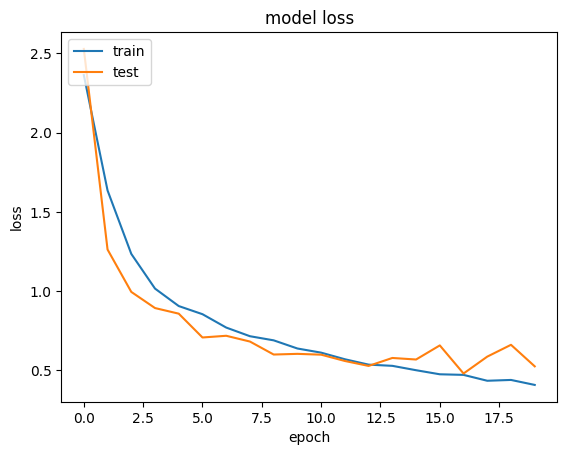

compile_metrics: 80.25%
74/74 - 3s - 34ms/step


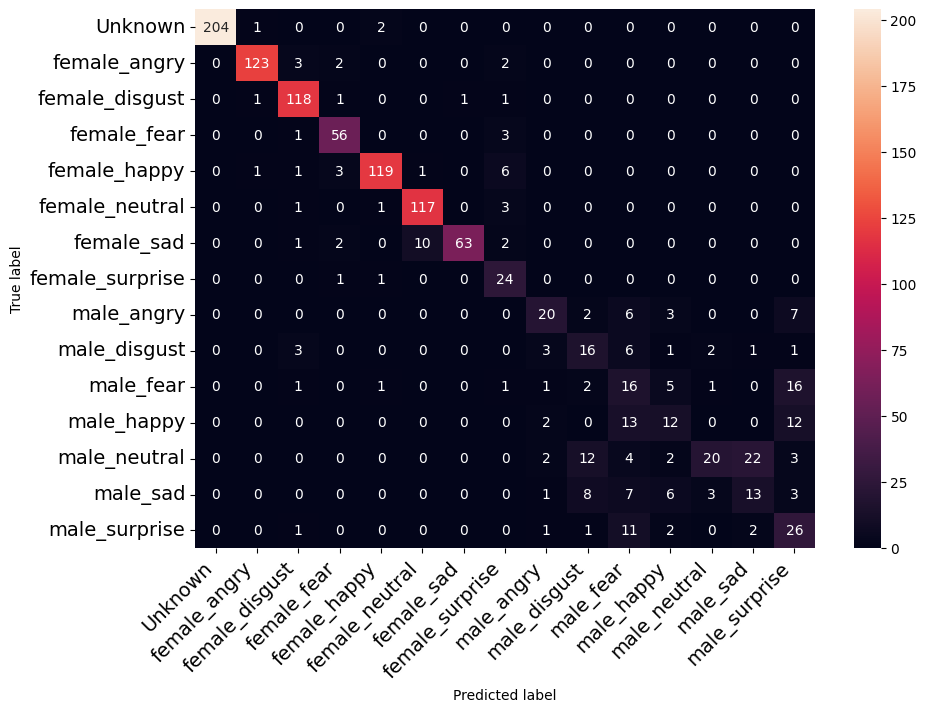

In [ ]:
results = get_results(model1_history,model,X_test,y_test, ref.labels.unique())
results.create_plot(model1_history)
results.create_results(model1)
results.confusion_results(X_test, y_test, ref.labels.unique(), model1)

Note that after applying 2D ConvNet we may got less accuracy but our validation loss increases drastically as well as our model is converging.

# MFCC with Augmentation

In [ ]:
sampling_rate=44100
audio_duration=2.5
n_mfcc = 20
mfcc_aug = prepare_data(ref, n = n_mfcc, aug = 1, mfcc = 1)

100%|██████████| 4720/4720 [05:25<00:00, 14.52it/s]


In [ ]:
# Split between train and test
X_train, X_test, y_train, y_test = train_test_split(mfcc_aug
                                                    , ref.labels
                                                    , test_size=0.25
                                                    , shuffle=True
                                                    , random_state=42
                                                   )

# one hot encode the target
lb = LabelEncoder()
y_train = to_categorical(lb.fit_transform(y_train))
y_test = to_categorical(lb.fit_transform(y_test))

# Normalization as per the standard NN process
# mean = np.mean(X_train, axis=0)
# std = np.std(X_train, axis=0)

# X_train = (X_train - mean)/std
# X_test = (X_test - mean)/std

# Build CNN model
model2 = get_2d_conv_model(n=n_mfcc)
model2_history = model2.fit(X_train, y_train, validation_data=(X_test, y_test),
                    batch_size=16, verbose = 2, epochs=20)

Epoch 1/20
222/222 - 29s - 129ms/step - acc: 0.2319 - loss: 2.3924 - val_acc: 0.2568 - val_loss: 2.9622
Epoch 2/20
222/222 - 16s - 72ms/step - acc: 0.4144 - loss: 1.7308 - val_acc: 0.5339 - val_loss: 1.4346
Epoch 3/20
222/222 - 16s - 71ms/step - acc: 0.5223 - loss: 1.4379 - val_acc: 0.5797 - val_loss: 1.1855
Epoch 4/20
222/222 - 16s - 71ms/step - acc: 0.5825 - loss: 1.2704 - val_acc: 0.6458 - val_loss: 1.0645
Epoch 5/20
222/222 - 15s - 69ms/step - acc: 0.6206 - loss: 1.1271 - val_acc: 0.6559 - val_loss: 0.9584
Epoch 6/20
222/222 - 16s - 72ms/step - acc: 0.6514 - loss: 1.0336 - val_acc: 0.6720 - val_loss: 0.9272
Epoch 7/20
222/222 - 16s - 74ms/step - acc: 0.6794 - loss: 0.9448 - val_acc: 0.6542 - val_loss: 0.9543
Epoch 8/20
222/222 - 16s - 71ms/step - acc: 0.6955 - loss: 0.8865 - val_acc: 0.7085 - val_loss: 0.7571
Epoch 9/20
222/222 - 15s - 69ms/step - acc: 0.7082 - loss: 0.8500 - val_acc: 0.6941 - val_loss: 0.8767
Epoch 10/20
222/222 - 15s - 70ms/step - acc: 0.7215 - loss: 0.8123 - val

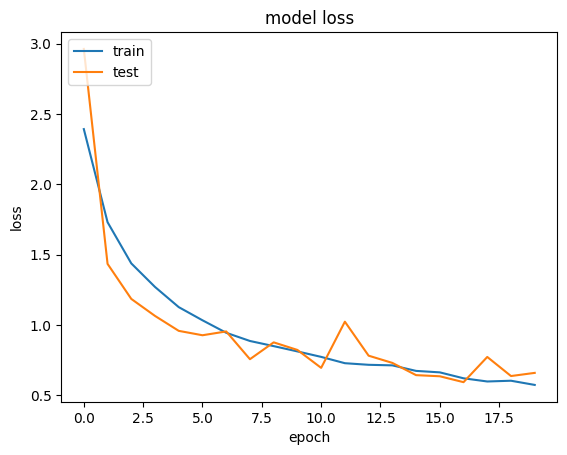

compile_metrics: 76.36%
74/74 - 2s - 29ms/step


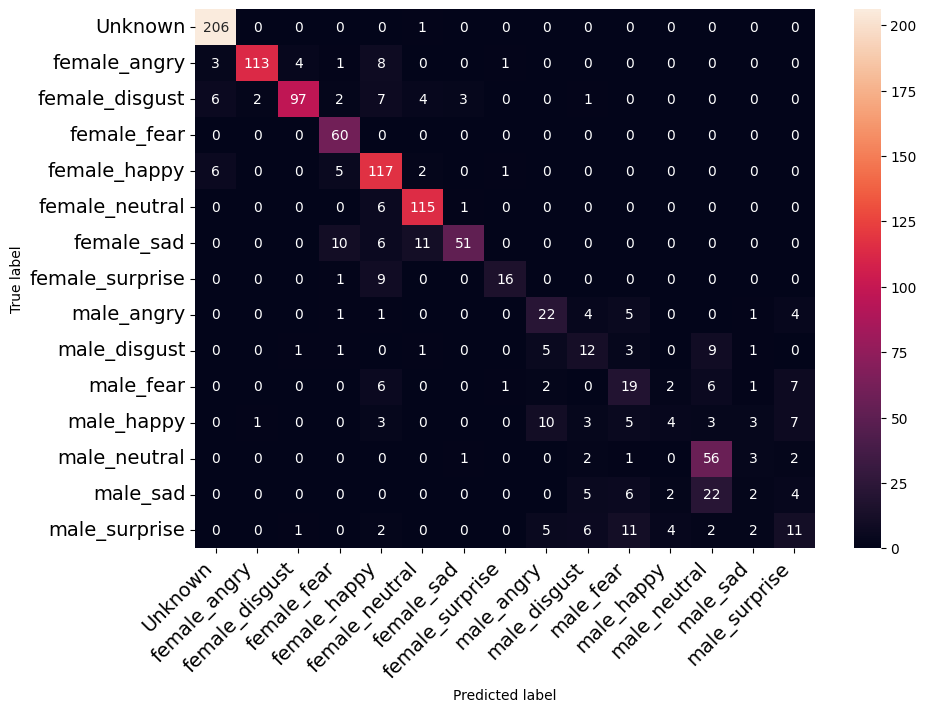

In [ ]:
results = get_results(model2_history,model2,X_test,y_test, ref.labels.unique())
results.create_plot(model2_history)
results.create_results(model2)
results.confusion_results(X_test, y_test, ref.labels.unique(), model2)

# Conclusion
**From the above observation we found that after adding augmented data to the dataset and we slighltly improve the dataset which is quite around 83% and validation accuracy is around 76% **

From all the models which is used to train we found that **MFCC without augmentation** higher precision
Accuracy=85%
validation Accuracy=81%
so we are going to save that model

In [ ]:
#Save weights to HDF5
filepath="Emotion_Model2.h5"
model1.save(filepath)

#Serialize to json format
model1_json=model1.to_json()
with open("model1.json","w") as json_file:
    json_file.write(model1_json)
print("Saved model to disk")


Saved model to disk


In [ ]:
#Loading json and create model
json_file=open("model1.json","r")
loaded_model_json=json_file.read()
json_file.close()
loaded_model=model_from_json(loaded_model_json)
#Load weights into new model
loaded_model.load_weights("Emotion_Model2.h5")
print("Loaded Model from disk")

#Evaluate Model
loaded_model.compile(loss='binary_crossentropy',optimizer='adam',metrics=['accuracy'])
score=loaded_model.evaluate(X_test, y_test, verbose=0)
print(loaded_model.metrics_names[1],score[1]*100)

Loaded Model from disk
compile_metrics 4.830508306622505



# Prediction on new data

In [ ]:
newData,newSR= librosa.load("/kaggle/input/urdu-language-speech-dataset/Neutral/SM20_F5_N09.wav")

FileNotFoundError: [Errno 2] No such file or directory: '/kaggle/input/urdu-language-speech-dataset/Neutral/SM20_F5_N09.wav'

This is my voice that I recorded and converted into .wav format

In [ ]:
ipd.Audio("/kaggle/input/urdu-language-speech-dataset/Neutral/SM20_F5_N09.wav")

In [ ]:
plt.figure(figsize=(15, 5))
librosa.display.waveshow(newData, sr=newSR)

In [ ]:
# Lets transform the dataset so we can apply the predictions
newData, newSR = librosa.load("/kaggle/input/urdu-language-speech-dataset/Neutral/SM20_F5_N09.wav"
                              ,duration=2.5
                              ,sr=44100
                              ,offset=0.5)

newSR = np.array(newSR)
mfccs = np.mean(librosa.feature.mfcc(y=newData, sr=newSR, n_mfcc=13),axis=0)
newdf = pd.DataFrame(data=mfccs).T
newdf

In [ ]:
newdf= np.expand_dims(newdf,axis=2)
print(newdf.shape)
newpred=model.predict(newdf)

In [ ]:
filename = filename = '/kaggle/working/labels'
infile = open(filename,'rb')
lb = pickle.load(infile)
infile.close()

# Get the final predicted label
final = newpred.argmax(axis=1)
final = final.astype(int).flatten()
final = (lb.inverse_transform((final)))
print(final) #emo(final) #gender(final)

In [ ]:
import numpy as np
import librosa
from tensorflow.keras.models import load_model

def preprocess_audio(file_path, n_mfcc=20, max_pad_len=216):
    """
    Preprocesses the audio file and extracts MFCC features.

    Parameters:
    - file_path (str): Path to the audio file.
    - n_mfcc (int): Number of MFCC features to extract.
    - max_pad_len (int): Maximum length of the MFCC sequence to pad/truncate.

    Returns:
    - mfccs (ndarray): Processed MFCC features with shape (n_mfcc, max_pad_len, 1).
    """
    try:
        audio, sample_rate = librosa.load(file_path, res_type='kaiser_fast', duration=2.5, sr=44100, offset=0.5)
        mfccs = librosa.feature.mfcc(y=audio, sr=sample_rate, n_mfcc=n_mfcc)

        # Padding or truncating the MFCC sequence to ensure uniform length
        pad_width = max_pad_len - mfccs.shape[1]
        if pad_width > 0:
            mfccs = np.pad(mfccs, pad_width=((0, 0), (0, pad_width)), mode='constant')
        else:
            mfccs = mfccs[:, :max_pad_len]

        mfccs = np.expand_dims(mfccs, axis=-1)  # Add channel dimension
        return mfccs
    except Exception as e:
        print(f"Error encountered while processing file: {file_path}")
        return None

def predict_emotion(model, file_path):
    """
    Predicts the emotion of the audio file using the trained model.

    Parameters:
    - model (tf.keras.Model): Trained Keras model for emotion classification.
    - file_path (str): Path to the audio file.

    Returns:
    - prediction (str): Predicted emotion label.
    """
    # Preprocess the audio file
    mfccs = preprocess_audio(file_path)
    if mfccs is None:
        return None

    # Expand dimensions to match the input shape of the model
    mfccs = np.expand_dims(mfccs, axis=0)

    # Make prediction
    predictions = model.predict(mfccs)
    predicted_label = np.argmax(predictions, axis=1)

    # Map the predicted label to the emotion
    emotion_map = {0: 'male_angry', 1: 'male_disgust', 2: 'male_fear', 3: 'male_happy', 4: 'male_neutral',
                   5: 'male_sad', 6: 'male_surprise', 7: 'female_angry', 8: 'female_disgust', 9: 'female_fear',
                   10: 'female_happy', 11: 'female_neutral', 12: 'female_sad', 13: 'female_surprise'}

    return emotion_map.get(predicted_label[0], "Unknown")

model = load_model('Emotion_Model2.h5')


file_path = '../../dataset/Crema/AudioWAV/1001_DFA_ANG_XX.wav'
predicted_emotion = predict_emotion(model, file_path)
print(f"Predicted Emotion: {predicted_emotion}")


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 486ms/step
Predicted Emotion: male_fear


In [ ]:
# Initialize the results dictionary
results = {}

# Path to the folder containing audio files
folder_path = '../../audios/TestAudios/TestAudios'

# Iterate over all files in the folder
for file_name in os.listdir(folder_path):
    if file_name.endswith('.wav'):  # Ensure the file is a WAV file
        file_path = os.path.join(folder_path, file_name)
        predicted_emotion = predict_emotion(model, file_path)
        results[file_path] = predicted_emotion
        print(f"File: {file_path}, Predicted Emotion: {predicted_emotion}")


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step
File: ../../audios/TestAudios/TestAudios\0013_000001n.wav, Predicted Emotion: female_fear
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step
File: ../../audios/TestAudios/TestAudios\0013_000351a.wav, Predicted Emotion: female_fear
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 77ms/step
File: ../../audios/TestAudios/TestAudios\0013_000701h.wav, Predicted Emotion: male_fear
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 64ms/step
File: ../../audios/TestAudios/TestAudios\0016_000001n.wav, Predicted Emotion: female_sad
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step
File: ../../audios/TestAudios/TestAudios\0016_000351a.wav, Predicted Emotion: male_fear
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step
File: ../../audios/TestAudios/TestAudios\0016_000701h.wav, Predicted Emotion: female_sad
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step
File: ../../audios/TestAudios/TestAudios\0019_000001n.wav, Predicted Emotion: female_fear
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 81ms/step
File: ../../audios/TestAudios/TestAudios\0019_000351a.wav, Predicted Emo